# R4 F2b: factorial ablation of smoothing, the GAM and the null model on the Sup. Fig. 1 simulations

Reviewer 4, points F1/F2. On the 100 simulated Visium slides of 05_01_simulated_benchmarking (seeds 0-99), seven
scorers (EnrichMap, AUCell, GSVA, ssGSEA, Z score, Scanpy, GSDensity) and the oracle truth are evaluated raw, smoothed,
GAM-corrected and smoothed + GAM-corrected (per-seed results of scripts/F2b_compute.py); the EnrichMap null
model is scored here on the same slides, contaminated gene sets and noise draws. Panels: classification, GAM mechanism,
example slide, leakage, concordance, robustness, GSDensity, gene weights and a replacement Sup. Fig. 1.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import glob

from matplotlib.cbook import boxplot_stats
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score

from helpers import (
    simulate_visium,
    f2b_spatial_conn,
    f2b_smooth,
    f2b_spatial_gam,
    f2b_gam_fitted,
    f2b_gam_residual,
    f2b_configurations,
    f2b_spatial_folds,
    f2b_boundary_mask,
    f2b_perturbations,
    f2b_noisy_adata,
    f2b_f1,
    f2b_classification_metrics,
    f2b_concordance_labels_smoothed,
    f2b_concordance_scores_smoothed,
    f2b_gearys_c,
    f2b_hop_distance,
    f2b_leakage_profile,
    f2b_leakage_summary,
    f2b_summarise,
    f2b_mean_ci,
    f2b_paired_table,
    f2b_vs_enrichmap,
    f2b_robustness_summary,
    f2b_show_robustness,
    f2b_robustness_area,
    f2b_headline_table,
    f2b_categorical_to_str,
    f2b_plot_benchmark_summary,
    f2b_factorial_pair,
    f2b_method_handles,
    f2b_config_handles,
    f2b_legend,
    f2b_dotplot,
    f2b_lineplot_by_config,
    f2b_dot_table,
    f2b_line_table,
    f2b_fixed_rule_strip,
    f2b_headline_curves,
    f2b_compact_layout,
)

In [3]:
sc.set_figure_params(frameon=False, fontsize=8)
sc.settings._vector_friendly = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)
sc.settings.figdir = figure_dir

# processed data directory
processed_data = working_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)


# per-seed factorial results (scripts/F2b_compute.py) and GSDensity labels of the simulated slides
f2b_dir = working_dir + "data/F2b/"
gsd_dir = working_dir + "data/gsd_cache/sims/"

In [5]:
colours = {
    "EnrichMap (null model)": "#2f0bdf",
    "EnrichMap (smoothing-only)": "#a393f8",
    "EnrichMap (GAM)": "#684bf6",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
    "EnrichMap (raw, no smoothing)": "#c6bbfc",
    "Truth (oracle)": "#000000",
}
weight_colours = {"uniform weights": "#1f0792", "SD weights": "#5433f5", "oracle log-FC weights": "#c6bbfc"}
map_size = 5
spot_size = 20

Smoothing **S** (6-NN mean, Eq. 3) and the GAM residual **I − H** (Eq. 4–5) depend only on the spot coordinates, so
both are applied to the raw score r of every scorer: `raw` = r, `smooth` = S r (for EnrichMap = **EnrichMap
(smoothing-only)**), `GAM` = (I − H) r and `smooth+GAM` = (I − H) S r (= **EnrichMap (GAM)**, the published default).
The **null model** (`em.tl.score(null_model=True)`, the default since 0.3.0) is not an operator on the raw score, so it
is a fifth configuration of EnrichMap only. **Truth (oracle)** is the binary label passed through the same operators;
`smooth+refGAM` subtracts the GAM fit of 20 expression-matched control-set scores. Summaries are mean ± SD over slides
unless stated; compact panels show means with 95% bootstrap CIs; paired tests are Wilcoxon signed-rank over slides.

In [6]:
# 1. Load the per-seed factorial results (GSVA noise: part gsva_noise, one repeat per level, seeds 0-9)
scorers = ["EnrichMap", "AUCell", "GSVA", "ssGSEA", "z-score", "scanpy", "GSDensity"]
configs = ["raw", "smooth", "GAM", "smooth+GAM"]
null_config = "null model"
configs_all = configs + [null_config]
methods = scorers + ["Truth (oracle)"]
method_order = methods + ["GSDensity (log1p)"]
config_order = configs_all + ["smooth+refGAM"]
key_metrics = [
    "AUROC", "AUPRC", "F1 (oracle threshold)", "F1 (top-k, prevalence-matched)",
    "F1 (spatial-block CV threshold)", "Boundary F1 (top-k)", "Moran's I", "Spatial coherence (top-k)",
]
null_rules = [
    ("F1 (z > 0)", "z > 0"), ("F1 (z > 1.96)", "z > 1.96"), ("F1 (p_empirical <= 0.05)", "p_empirical ≤ 0.05"),
]

parts = ["fast", "ssgsea", "gsva", "gsva_noise", "gsd"]
records = [pd.read_pickle(f) for p in parts for f in sorted(glob.glob(f2b_dir + f"{p}/seed*.pkl"))]
tables = {
    key: pd.DataFrame([row for r in records for row in r.get(key, [])])
    for key in ["clf", "conc", "contam", "noise", "gw", "diag", "gsd", "gsd_kld"]
}
gw, diag, gsd, kld = tables["gw"], tables["diag"], tables["gsd"], tables["gsd_kld"]
print({p: len(glob.glob(f2b_dir + f"{p}/seed*.pkl")) for p in parts})

{'fast': 100, 'ssgsea': 100, 'gsva': 100, 'gsva_noise': 10, 'gsd': 100}


In [7]:
# 2. EnrichMap null model on the same slides, contaminated gene sets and noise draws
variants = {"null": dict(null_model=True, correct_spatial_covariates=False, compute_q_vals=True)}
fractions = [0.0, 0.5, 1.0, 2.0, 4.0]
noise_levels = [0.0, 0.5, 1.0, 2.0, 3.0]
n_repeats = 3
conc_k = [1, 3, 5, 7, 10]

null_rows = {"clf": [], "conc": [], "contam": [], "noise": []}
slides = {}
for seed in range(100):
    adata, sig_genes, fold_changes, target_label = simulate_visium(seed=seed)
    y = (adata.obs["cluster"] == target_label).values.astype(int)
    xy = np.asarray(adata.obsm["spatial"])
    conn = f2b_spatial_conn(xy)
    folds = f2b_spatial_folds(xy, seed=seed)
    bmask = f2b_boundary_mask(conn, y)
    contam_sets, noise_draws, gene_idx = f2b_perturbations(
        adata, sig_genes, seed, fractions, noise_levels, n_repeats,
    )
    row = dict(seed=seed, method="EnrichMap", config=null_config)

    # clean score, null mean, moderated null SD and empirical p
    em.tl.score(adata, gene_set=sig_genes, score_key="target_null", **variants["null"])
    z = adata.obs["target_null_score"].values.astype(np.float64)
    info = adata.uns["null_model"]["target_null"]
    p_emp = info["p_empirical"].astype(np.float64)
    slides[seed] = dict(
        xy=xy, y=y, conn=conn, null=z, null_mean=info["null_mean"].astype(np.float64),
        null_sd=info["null_sd"].astype(np.float64), p_empirical=p_emp,
    )
    for metric, v in f2b_classification_metrics(y, z, conn, folds, bmask).items():
        null_rows["clf"].append(dict(row, metric=metric, value=float(v)))
    for rule, pred in {"z > 0": z > 0, "z > 1.96": z > 1.96, "p_empirical <= 0.05": p_emp <= 0.05}.items():
        null_rows["clf"].append(dict(row, metric=f"F1 ({rule})", value=f2b_f1(y, pred)))
        null_rows["clf"].append(dict(
            row, metric=f"fraction of background spots positive ({rule})", value=float(pred[y == 0].mean()),
        ))
    for k, rho in f2b_concordance_labels_smoothed(z, y, conn, conc_k).items():
        null_rows["conc"].append(dict(row, k=k, variant="labels smoothed (as implemented)", rho=rho))
    for k, rho in f2b_concordance_scores_smoothed(z, y, conn, conc_k).items():
        null_rows["conc"].append(dict(row, k=k, variant="scores smoothed (Methods text)", rho=rho))

    # contamination: random genes added to the signature
    for (frac, rep), genes in contam_sets.items():
        if frac == 0:
            s = z
        else:
            em.tl.score(adata, gene_set=genes, score_key="contaminated_null", **variants["null"])
            s = adata.obs["contaminated_null_score"].values.astype(np.float64)
        null_rows["contam"].append(dict(
            row, level=frac, rep=rep, rho_self=float(stats.spearmanr(z, s).correlation),
            auroc=float(roc_auc_score(y, s)), auprc=float(average_precision_score(y, s)),
        ))

    # noise on the signature genes
    for (level, rep), draw in noise_draws.items():
        if level == 0:
            s = z
        else:
            adata_noisy = f2b_noisy_adata(adata, gene_idx, draw)
            em.tl.score(adata_noisy, gene_set=sig_genes, score_key="noisy_null", **variants["null"])
            s = adata_noisy.obs["noisy_null_score"].values.astype(np.float64)
        null_rows["noise"].append(dict(
            row, level=level, rep=rep, rho_self=float(stats.spearmanr(z, s).correlation),
            auroc=float(roc_auc_score(y, s)), auprc=float(average_precision_score(y, s)),
        ))

    # alternative gene weights under the null model (Sup. Fig. 1d arm)
    X_sig = adata[:, sig_genes].X.toarray()
    alt_weights = {
        "EnrichMap (uniform weights)": {g: 1.0 for g in sig_genes},
        "EnrichMap (SD weights)": dict(zip(sig_genes, X_sig.std(axis=0).astype(np.float64))),
        "EnrichMap (oracle log-FC weights)": dict(zip(sig_genes, np.log(fold_changes))),
    }
    for name, weights in alt_weights.items():
        em.tl.score(adata, gene_weights={"weights_null": weights}, **variants["null"])
        s = adata.obs["weights_null_score"].values.astype(np.float64)
        for metric, v in f2b_classification_metrics(y, s, conn, folds, bmask).items():
            null_rows["clf"].append(dict(row, method=name, metric=metric, value=float(v)))

clf = pd.concat([tables["clf"], pd.DataFrame(null_rows["clf"])], ignore_index=True)
conc = pd.concat([tables["conc"], pd.DataFrame(null_rows["conc"])], ignore_index=True)
contam = pd.concat([tables["contam"], pd.DataFrame(null_rows["contam"])], ignore_index=True)
noise = pd.concat([tables["noise"], pd.DataFrame(null_rows["noise"])], ignore_index=True)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring target_null: 20/20 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring target_null: 20/20 genes found: 100%|██████████| 1/1 [00:00<00:00, 35.29it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring contaminated_null: 30/30 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring contaminated_null: 30/30 genes found: 100%|██████████| 1/1 [00:00<00:00, 34.07it/s]

... (8,390 outputs left out)

Scoring weights_null: 20/20 genes found: 100%|██████████| 1/1 [00:00<00:00, 480.34it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring weights_null: 20/20 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring weights_null: 20/20 genes found: 100%|██████████| 1/1 [00:00<00:00, 462.44it/s]

In [8]:
# 3. Published labels, palette keys and configuration markers
labels = {"z-score": "Z score", "scanpy": "Scanpy"}

# EnrichMap configurations take the colour of the matching variant; unsmoothed ones (raw, GAM) the light shade
em_colour_key = {
    "raw": "EnrichMap (raw, no smoothing)", "GAM": "EnrichMap (raw, no smoothing)",
    "smooth": "EnrichMap (smoothing-only)", "smooth+GAM": "EnrichMap (GAM)", null_config: "EnrichMap (null model)",
}
plot_style = {
    "colours": colours,
    "colour_key": {
        (m, c): em_colour_key[c] if m == "EnrichMap" else labels.get(m, m) for m in methods for c in configs_all
    },
    "markers": {"raw": "o", "smooth": "s", "GAM": "^", "smooth+GAM": "D", null_config: "P"},
    "config_labels": {
        "smooth": "smooth (EnrichMap: smoothing-only)", "smooth+GAM": "smooth+GAM (EnrichMap: GAM)",
        null_config: "null model (EnrichMap only)",
    },
    "labels": labels,
    "null_config": null_config,
}

# headline configuration of every method
headline = [
    ("EnrichMap", null_config, "EnrichMap (null model)"), ("EnrichMap", "smooth", "EnrichMap (smoothing-only)"),
    ("EnrichMap", "smooth+GAM", "EnrichMap (GAM)"), ("AUCell", "raw", "AUCell"), ("GSVA", "raw", "GSVA"),
    ("ssGSEA", "raw", "ssGSEA"), ("z-score", "raw", "Z score"), ("scanpy", "raw", "Scanpy"),
    ("GSDensity", "raw", "GSDensity"),
]

In [9]:
# 4. Slides per arm (GSVA dominated the factorial run, so the slow arms ran on fewer slides)
run_log = []
for m in methods + ["EnrichMap (null model)"]:
    row = {"method": m}
    for arm, df in [
        ("classification + concordance", clf), ("contamination (0,.5,1,2,4 x; 3 reps)", contam), ("noise", noise),
    ]:
        if m == "EnrichMap (null model)":
            sub = df[(df.method == "EnrichMap") & (df.config == null_config)]
        else:
            sub = df[(df.method == m) & (df.config != null_config)]
        seeds = sorted(sub.seed.unique())
        row[arm] = f"{len(seeds)} ({min(seeds)}–{max(seeds)})" if seeds else "0"
    reps = sub.groupby("level").rep.nunique()
    row["noise levels (reps)"] = ", ".join(f"{level:g}({n})" for level, n in reps.items())
    run_log.append(row)
run_log = pd.DataFrame(run_log).set_index("method")
print(run_log.to_string())

                       classification + concordance contamination (0,.5,1,2,4 x; 3 reps)       noise             noise levels (reps)
method                                                                                                                              
EnrichMap                                100 (0–99)                           100 (0–99)  100 (0–99)  0(3), 0.5(3), 1(3), 2(3), 3(3)
AUCell                                   100 (0–99)                           100 (0–99)  100 (0–99)  0(3), 0.5(3), 1(3), 2(3), 3(3)
GSVA                                     100 (0–99)                           100 (0–99)    10 (0–9)  0(3), 0.5(1), 1(1), 2(1), 3(1)
ssGSEA                                   100 (0–99)                           100 (0–99)   20 (0–19)  0(3), 0.5(3), 1(3), 2(3), 3(3)
z-score                                  100 (0–99)                           100 (0–99)  100 (0–99)  0(3), 0.5(3), 1(3), 2(3), 3(3)
scanpy                                   100 (0–99)                  

In [10]:
# 5. The GAM operator on these slides (share of the target-indicator variance absorbed by the default GAM)
print(diag[["n_spots", "prevalence", "gam_edof", "gam_r2_labels", "gam_r2_smoothed_labels", "morans_truth"]]
      .describe().round(3).to_string())


        n_spots  prevalence  gam_edof  gam_r2_labels  gam_r2_smoothed_labels  morans_truth
count   100.000     100.000   100.000        100.000                 100.000       100.000
mean   2913.990       0.254    35.568          0.833                   0.929         0.871
std     760.952       0.092     2.324          0.125                   0.055         0.129
min    1554.000       0.079    31.033          0.162                   0.532         0.168
25%    2295.000       0.188    33.686          0.821                   0.929         0.859
50%    3039.000       0.239    36.513          0.881                   0.948         0.916
75%    3584.000       0.308    37.190          0.898                   0.954         0.935
max    4012.000       0.534    38.839          0.928                   0.963         0.959


In [11]:
# 6. Per-slide Geary's C and leakage rings from the stored clean scores (every scorer x configuration)
geary, leak, prof = [], [], []
for seed in range(100):
    xy, y, conn = slides[seed]["xy"], slides[seed]["y"], slides[seed]["conn"]
    gam = f2b_spatial_gam(xy)
    mask = y.astype(bool)
    dist = f2b_hop_distance(conn, mask)
    far = dist >= 6
    cfg_scores = {}
    for part in ["fast", "ssgsea", "gsva", "gsd"]:
        stored = np.load(f2b_dir + f"{part}/seed{seed:03d}_scores.npz")
        for key in stored.files:
            m = key.split("|", 1)[1]
            if key.startswith("clean|") and m in methods:
                for cfg, s in f2b_configurations(stored[key].astype(np.float64), conn, gam).items():
                    cfg_scores[(m, cfg)] = s
    cfg_scores[("EnrichMap", null_config)] = slides[seed]["null"]
    for (m, cfg), s in cfg_scores.items():
        geary.append(dict(seed=seed, method=m, config=cfg, metric="Geary's C", value=f2b_gearys_c(s, conn)))
        mu_far, sd_far = s[far].mean(), s[far].std()
        ring_z = {d: (s[dist == d].mean() - mu_far) / sd_far for d in range(1, 9)}
        leak.append(dict(
            seed=seed, method=m, config=cfg, **f2b_leakage_summary(s, mask, dist),
            **{
                "inside contrast (far-background SD)": (s[mask].mean() - mu_far) / sd_far,
                "halo rings 1-3 (far-background SD)": float(np.mean([ring_z[1], ring_z[2], ring_z[3]])),
                "min over rings 1-8 (far-background SD)": float(min(ring_z.values())),
            },
        ))
        for ring, v in f2b_leakage_profile(s, mask, dist).items():
            prof.append(dict(seed=seed, method=m, config=cfg, ring=ring, L=v, z=ring_z[ring]))
geary, leak, prof = pd.DataFrame(geary), pd.DataFrame(leak), pd.DataFrame(prof)
clf = pd.concat([clf, geary], ignore_index=True)
print(f"Geary's C rows: {len(geary)}; leakage rows: {len(leak)}; slides: {leak.seed.nunique()}")

Geary's C rows: 3300; leakage rows: 3300; slides: 100


In [12]:
# 7. Classification: every scorer x every configuration (mean ± SD over slides)
summ = f2b_summarise(
    clf,
    key_metrics + ["Geary's C", "F1 (median threshold)", "F1 (Otsu, label-free)", "KS"] + [r for r, _ in null_rules]
    + [f"fraction of background spots positive ({r})" for r in ["z > 0", "z > 1.96", "p_empirical <= 0.05"]],
    scorers + [
        "GSDensity (log1p)", "Truth (oracle)", "EnrichMap (uniform weights)", "EnrichMap (SD weights)",
        "EnrichMap (oracle log-FC weights)",
    ],
    config_order,
)
summ.to_csv(working_dir + "data/F2b/F2b_classification_summary.csv", index=False)
show = summ[summ.metric.isin([
    "AUROC", "AUPRC", "F1 (oracle threshold)", "F1 (top-k, prevalence-matched)",
    "F1 (spatial-block CV threshold)", "Boundary F1 (top-k)", "Moran's I", "Geary's C",
])].copy()
show["mean ± SD"] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(show["mean"], show["sd"])]
tab = show.pivot_table(index=["method", "config"], columns="metric", values="mean ± SD", aggfunc="first")
tab = tab.reindex([(m, c) for m in scorers + ["GSDensity (log1p)", "Truth (oracle)"] for c in config_order
                   if (m, c) in tab.index])
print(tab.to_string())
print("n seeds:", summ[summ.metric == "AUROC"].groupby("method")["n"].max().to_dict())
nr = summ[(summ.method == "EnrichMap") & (summ.config == null_config) & summ.metric.str.contains(r"\(z|\(p_emp")]
print("\nEnrichMap (null model), fixed label-free calls:")
print(nr[["metric", "n", "mean", "sd"]].round(3).to_string(index=False))

metric                                   AUPRC          AUROC Boundary F1 (top-k) F1 (oracle threshold) F1 (spatial-block CV threshold) F1 (top-k, prevalence-matched)      Geary's C       Moran's I
method            config                                                                                                                                                                             
EnrichMap         raw            0.910 ± 0.045  0.960 ± 0.015       0.881 ± 0.043         0.835 ± 0.047                   0.818 ± 0.054                  0.830 ± 0.049  0.508 ± 0.097   0.491 ± 0.097
                  smooth         0.937 ± 0.118  0.978 ± 0.039       0.677 ± 0.062         0.919 ± 0.098                   0.913 ± 0.102                  0.913 ± 0.106  0.110 ± 0.055   0.890 ± 0.055
                  GAM            0.422 ± 0.092  0.613 ± 0.070       0.759 ± 0.065         0.443 ± 0.090                   0.394 ± 0.124                  0.402 ± 0.073  0.965 ± 0.025   0.034 ± 0.025
          

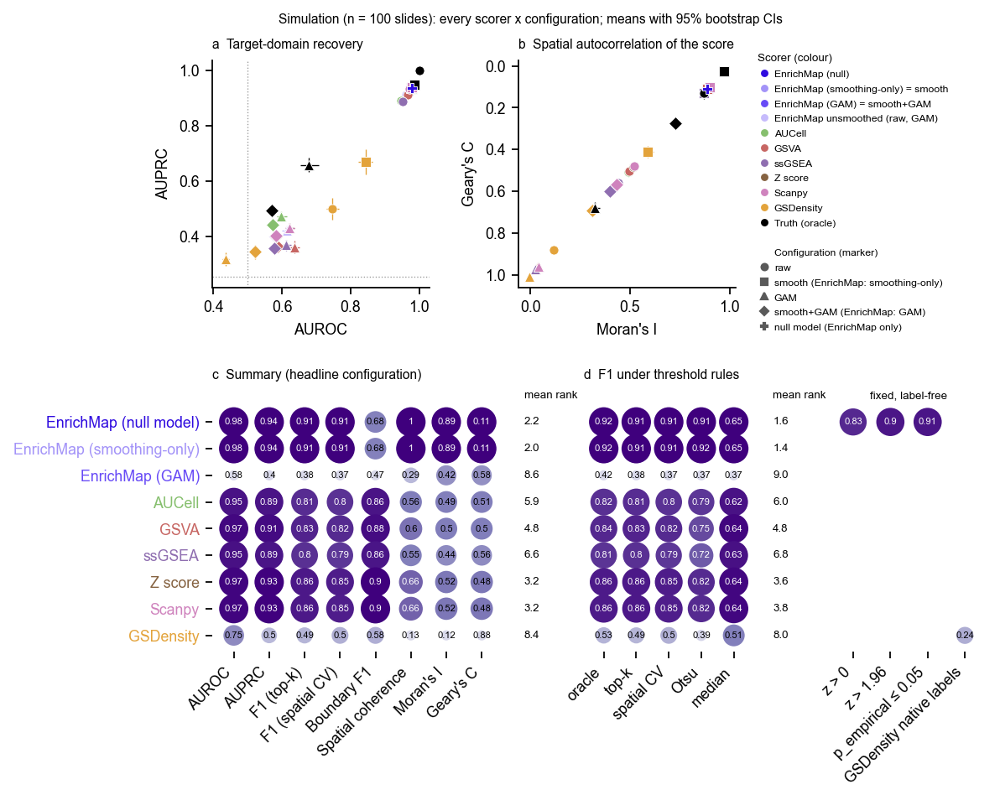

        method     config  AUROC  AUROC_lo  AUROC_hi  AUPRC  Moran's I  Geary's C
     EnrichMap        raw  0.960     0.958     0.963  0.910      0.491      0.508
     EnrichMap     smooth  0.978     0.969     0.985  0.937      0.890      0.110
     EnrichMap        GAM  0.613     0.601     0.628  0.422      0.034      0.965
     EnrichMap smooth+GAM  0.579     0.572     0.587  0.400      0.423      0.578
     EnrichMap null model  0.978     0.969     0.984  0.937      0.888      0.111
     GSDensity        raw  0.747     0.729     0.766  0.500      0.118      0.882
     GSDensity     smooth  0.843     0.821     0.864  0.671      0.590      0.410
     GSDensity        GAM  0.435     0.426     0.445  0.318     -0.007      1.007
     GSDensity smooth+GAM  0.520     0.516     0.525  0.344      0.309      0.691
Truth (oracle)        raw  1.000     1.000     1.000  1.000      0.871      0.129
Truth (oracle)     smooth  0.985     0.978     0.991  0.947      0.973      0.027
Truth (oracle)  

In [13]:
# 8. Classification figure (compact): AUROC vs AUPRC, Moran's I vs Geary's C, summary and threshold rules
clf_w = clf.pivot_table(index=["seed", "method", "config"], columns="metric", values="value").reset_index()
pair_metrics = key_metrics + ["Geary's C", "F1 (Otsu, label-free)", "F1 (median threshold)"] + [r for r, _ in null_rules]
pair_tab = f2b_mean_ci(
    clf_w[clf_w.method.isin(methods) & clf_w.config.isin(configs_all)], pair_metrics, method_order, config_order,
)

# headline configuration of every method (summary panel and threshold rules)
head = pd.concat([
    pair_tab[(pair_tab.method == m) & (pair_tab.config == c)].assign(label=label) for m, c, label in headline
]).set_index("label")
bench_cols = {
    "AUROC": "AUROC", "AUPRC": "AUPRC", "F1 (top-k, prevalence-matched)": "F1 (top-k)",
    "F1 (spatial-block CV threshold)": "F1 (spatial CV)", "Boundary F1 (top-k)": "Boundary F1",
    "Spatial coherence (top-k)": "Spatial coherence", "Moran's I": "Moran's I", "Geary's C": "Geary's C",
}
bench_clf = head[list(bench_cols)].rename(columns=bench_cols)
rules = [
    ("F1 (oracle threshold)", "oracle"), ("F1 (top-k, prevalence-matched)", "top-k"),
    ("F1 (spatial-block CV threshold)", "spatial CV"), ("F1 (Otsu, label-free)", "Otsu"),
    ("F1 (median threshold)", "median"),
]
e_rules = head[[r for r, _ in rules]].rename(columns=dict(rules))
e_fixed = head[[r for r, _ in null_rules]].rename(columns=dict(null_rules))
gsd_native = gsd[gsd.setting == "default"].set_index("seed")["native_label_F1"]
e_fixed["GSDensity native labels"] = np.nan
e_fixed.loc["GSDensity", "GSDensity native labels"] = gsd_native.mean()
for c in e_fixed.columns[:3]:
    e_fixed.loc[e_fixed.index != "EnrichMap (null model)", c] = np.nan
prevalence = diag.prevalence.mean()

fig = plt.figure(figsize=(7.4, 5.8))
gs = gridspec.GridSpec(2, 3, figure=fig, width_ratios=[1, 1, 0.75], height_ratios=[1, 1.15], wspace=0.45, hspace=0.42)
ax = fig.add_subplot(gs[0, 0])
src_a = f2b_factorial_pair(ax, pair_tab, "AUROC", "AUPRC", methods, configs_all, plot_style, ref_x=0.5, ref_y=prevalence)
ax.set_title("a  Target-domain recovery", fontsize=7, loc="left")
ax = fig.add_subplot(gs[0, 1])
src_b = f2b_factorial_pair(ax, pair_tab, "Moran's I", "Geary's C", methods, configs_all, plot_style, invert_y=True)
ax.set_title("b  Spatial autocorrelation of the score", fontsize=7, loc="left")
f2b_legend(ax, methods, configs_all, plot_style, bbox=(1.08, 1.05))
sub = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1, :], width_ratios=[8.6, 5.4, 4.0], wspace=0.15)
ax = fig.add_subplot(sub[0])
f2b_plot_benchmark_summary(bench_clf, ax, colours, lower_is_better=("Geary's C",))
ax.set_title("c  Summary (headline configuration)", fontsize=7, loc="left")
ax = fig.add_subplot(sub[1])
f2b_plot_benchmark_summary(e_rules, ax, colours)
ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)
ax.set_title("d  F1 under threshold rules", fontsize=7, loc="left")
f2b_fixed_rule_strip(fig.add_subplot(sub[2]), e_fixed)
fig.suptitle("Simulation (n = 100 slides): every scorer x configuration; means with 95% bootstrap CIs",
             fontsize=7, y=0.97)
plt.savefig(figure_dir + "F2b_classification_factorial.pdf", bbox_inches="tight")
plt.show()

pd.concat({
    "a": src_a,
    "b": src_b,
    "c": bench_clf.reset_index().rename(columns={"label": "method"}),
    "d": pd.concat([e_rules, e_fixed], axis=1).reset_index().rename(columns={"label": "method"}),
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_classification_factorial.csv", index=False)

print(pair_tab[pair_tab.method.isin(["EnrichMap", "GSDensity", "Truth (oracle)"])][
    ["method", "config", "AUROC", "AUROC_lo", "AUROC_hi", "AUPRC", "Moran's I", "Geary's C"]].round(3).to_string(index=False))
print("\nsummary (headline configurations):\n", bench_clf.round(3).to_string())
print("\nthreshold rules:\n", pd.concat([e_rules, e_fixed], axis=1).round(3).to_string())

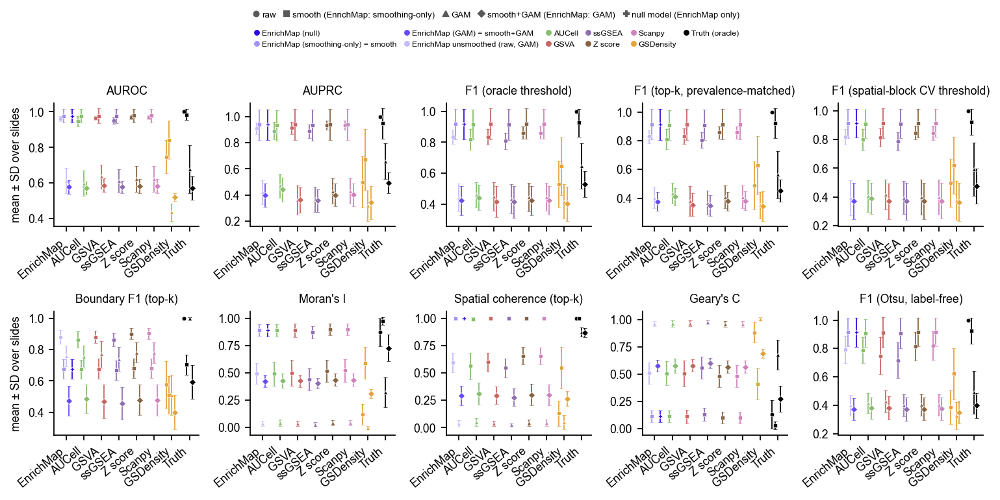

In [14]:
# 9. Classification figure (full): every metric, scorer and configuration (mean ± SD over slides)
full_metrics = key_metrics + ["Geary's C", "F1 (Otsu, label-free)"]
fig, axes = plt.subplots(2, 5, figsize=(9.6, 4.6))
for i, (ax, met) in enumerate(zip(axes.ravel(), full_metrics)):
    f2b_dotplot(ax, summ, met, methods, configs_all, plot_style, err="sd")
    if i % 5 == 0:
        ax.set_ylabel("mean ± SD over slides")
    ax.grid(False)
    sns.despine(ax=ax)
fig.legend(handles=f2b_config_handles(configs_all, plot_style), loc="upper center", ncol=5, frameon=False, fontsize=6,
           bbox_to_anchor=(0.5, 1.04))
fig.legend(handles=f2b_method_handles(methods, configs_all, plot_style), loc="upper center", ncol=6, frameon=False,
           fontsize=5.5, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.savefig(figure_dir + "F2b_classification_factorial_full.pdf", bbox_inches="tight")
plt.show()

pd.concat({
    chr(97 + i): f2b_dot_table(summ, met, methods, configs_all, labels, err="sd").assign(metric=met)
    for i, met in enumerate(full_metrics)
}, names=["panel", None]).reset_index(level="panel").to_csv(
    source_dir + "F2b_classification_factorial_full.csv", index=False,
)

In [15]:
# 10. Paired effect of the GAM, of smoothing and of the null model for every scorer
# delta = metric(with operator) - metric(without), paired by slide; 95% CI = t-interval; p = Wilcoxon signed-rank
contrasts = {
    "smooth+GAM vs smooth": ("smooth", "smooth+GAM"), "GAM vs raw": ("raw", "GAM"),
    "smooth vs raw": ("raw", "smooth"), "smooth+refGAM vs smooth": ("smooth", "smooth+refGAM"),
    "null model vs smooth": ("smooth", null_config), "null model vs smooth+GAM": ("smooth+GAM", null_config),
}
pt = f2b_paired_table(clf, key_metrics + ["Geary's C", "KS"], scorers + ["GSDensity (log1p)", "Truth (oracle)"], contrasts)
fmt = pt.copy()
fmt["Δ (95% CI)"] = [
    f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]" for d, lo, hi in zip(fmt["mean diff"], fmt["95% CI low"], fmt["95% CI high"])
]
for met in ["AUROC", "F1 (top-k, prevalence-matched)", "Moran's I"]:
    print(f"\n=== {met} ===")
    print(
        fmt[fmt.metric == met].pivot_table(index="method", columns="contrast", values="Δ (95% CI)", aggfunc="first")
        .reindex(scorers + ["GSDensity (log1p)", "Truth (oracle)"]).to_string()
    )
print("\nfraction of seeds where the GAM improved AUROC (smooth+GAM vs smooth):")
print(
    pt[(pt.metric == "AUROC") & (pt.contrast == "smooth+GAM vs smooth")]
    .set_index("method")[["n seeds", "frac seeds improved", "wilcoxon p"]].to_string()
)
print("\nEnrichMap null model vs smooth and vs smooth+GAM:")
print(
    pt[(pt.method == "EnrichMap") & pt.contrast.str.startswith("null")]
    [["metric", "contrast", "mean without", "mean with", "mean diff", "95% CI low", "95% CI high",
      "frac seeds improved", "wilcoxon p"]].round(4).to_string(index=False)
)


=== AUROC ===
contrast                        GAM vs raw     null model vs smooth null model vs smooth+GAM            smooth vs raw     smooth+GAM vs smooth  smooth+refGAM vs smooth
method                                                                                                                                                                 
EnrichMap          -0.347 [-0.361, -0.334]  -0.000 [-0.000, +0.000]  +0.399 [+0.390, +0.408]  +0.017 [+0.009, +0.026]  -0.399 [-0.408, -0.390]  +0.000 [+0.000, +0.000]
AUCell             -0.348 [-0.361, -0.335]                      NaN                      NaN  +0.032 [+0.022, +0.041]  -0.405 [-0.414, -0.397]                      NaN
GSVA               -0.329 [-0.343, -0.316]                      NaN                      NaN  +0.013 [+0.004, +0.021]  -0.390 [-0.399, -0.381]                      NaN
ssGSEA             -0.338 [-0.351, -0.325]                      NaN                      NaN  +0.025 [+0.016, +0.034]  -0.398 [-0.407, -0.389]   

In [16]:
# 11. Mechanism: the GAM removes the domain itself (per slide, and on seed 0); the null model does not
d_em = clf[(clf.metric == "AUROC") & (clf.config.isin(["smooth", "smooth+GAM", null_config]))].pivot_table(
    index=["method", "seed"], columns="config", values="value",
)
mech = pd.concat([
    (d_em["smooth+GAM"] - d_em["smooth"]).rename("dAUROC").reset_index().assign(contrast="smooth+GAM − smooth"),
    (d_em[null_config] - d_em["smooth"]).rename("dAUROC").reset_index().assign(contrast="null model − smooth"),
]).dropna(subset=["dAUROC"])
mech = mech.merge(diag[["seed", "gam_r2_smoothed_labels", "gam_r2_labels", "prevalence", "n_spots"]], on="seed")
mech_rho = []
for m, con in [("EnrichMap", "smooth+GAM − smooth"), ("Truth (oracle)", "smooth+GAM − smooth"),
               ("EnrichMap", "null model − smooth")]:
    s = mech[(mech.method == m) & (mech.contrast == con)]
    mech_rho.append({
        "method": m, "contrast": con, "n": len(s), "median dAUROC": s.dAUROC.median(),
        "Spearman(R2_GAM(smoothed truth), dAUROC)": stats.spearmanr(s.gam_r2_smoothed_labels, s.dAUROC).correlation,
    })
print(pd.DataFrame(mech_rho).round(4).to_string(index=False))

# example slide (seed 0): what the GAM and the null model take away
adata_0, sig_0, fc_0, target_0 = simulate_visium(seed=0)
y0 = (adata_0.obs["cluster"] == target_0).values.astype(float)
xy0, conn0, null0 = slides[0]["xy"], slides[0]["conn"], slides[0]
gam0 = f2b_spatial_gam(xy0)
raw0 = np.load(f2b_dir + "fast/seed000_scores.npz")["clean|EnrichMap"]
sm0 = f2b_smooth(raw0, conn0)
fit0 = f2b_gam_fitted(gam0, sm0)
res0 = f2b_gam_residual(gam0, sm0)
dist0 = f2b_hop_distance(conn0, y0.astype(bool))
edge0 = dist0 == 1
for name, v in [("S r", sm0), ("GAM fit H S r", fit0), ("null mean", null0["null_mean"]), ("null SD", null0["null_sd"]),
                ("null-model z", null0["null"])]:
    print(f"seed 0 {name:14s}: inside {v[y0 == 1].mean():+.3f} | ring 1 {v[edge0].mean():+.3f} | "
          f">= 6 rings {v[dist0 >= 6].mean():+.3f}")

# null-model z of target and background spots per slide (controls are shifted to the signature's slide-wide level)
zlev = []
for seed in range(100):
    z, in_t = slides[seed]["null"], slides[seed]["y"].astype(bool)
    zlev.append({
        "seed": seed, "prevalence": in_t.mean(), "mean z, target": z[in_t].mean(), "mean z, background": z[~in_t].mean(),
        "target z > 1.96": (z[in_t] > 1.96).mean(), "background z > 1.96": (z[~in_t] > 1.96).mean(),
        "background z < -1.96": (z[~in_t] < -1.96).mean(),
    })
zlev = pd.DataFrame(zlev)
print(zlev.drop(columns="seed").describe().loc[["mean", "50%", "min", "max"]].round(3).to_string())
print(f"Spearman(prevalence, mean background z) = {stats.spearmanr(zlev.prevalence, zlev['mean z, background']).correlation:.3f}")

        method            contrast   n  median dAUROC  Spearman(R2_GAM(smoothed truth), dAUROC)
     EnrichMap smooth+GAM − smooth 100        -0.4145                                   -0.8673
Truth (oracle) smooth+GAM − smooth 100        -0.4420                                   -0.9236
     EnrichMap null model − smooth 100        -0.0000                                    0.0834


seed 0 S r           : inside +1.299 | ring 1 +0.975 | >= 6 rings +0.789
seed 0 GAM fit H S r : inside +1.275 | ring 1 +1.005 | >= 6 rings +0.785
seed 0 null mean     : inside +0.928 | ring 1 +0.938 | >= 6 rings +0.932
seed 0 null SD       : inside +0.087 | ring 1 +0.087 | >= 6 rings +0.088
seed 0 null-model z  : inside +4.286 | ring 1 +0.426 | >= 6 rings -1.632
      prevalence  mean z, target  mean z, background  target z > 1.96  background z > 1.96  background z < -1.96
mean       0.254           4.587              -1.563            0.894                0.022                 0.407
50%        0.239           4.556              -1.554            0.919                0.015                 0.377
min        0.079           0.927              -3.070            0.250                0.003                 0.073
max        0.534           6.959              -0.067            0.974                0.127                 0.860
Spearman(prevalence, mean background z) = -0.933


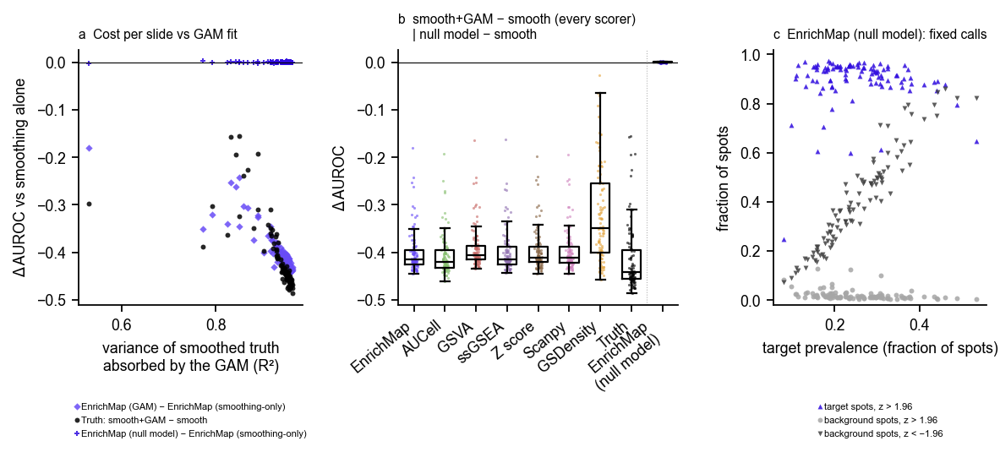

In [17]:
# 12. Mechanism figure: per-slide cost of the GAM, and the null model
em_colour = {cfg: colours[em_colour_key[cfg]] for cfg in configs_all}
mech_series = [
    ("EnrichMap", "smooth+GAM − smooth", "EnrichMap (GAM) − EnrichMap (smoothing-only)", em_colour["smooth+GAM"], "D"),
    ("Truth (oracle)", "smooth+GAM − smooth", "Truth: smooth+GAM − smooth", colours["Truth (oracle)"], "o"),
    ("EnrichMap", "null model − smooth", "EnrichMap (null model) − EnrichMap (smoothing-only)", em_colour[null_config], "P"),
]
box_groups = [
    (m, "smooth+GAM − smooth", colours[plot_style["colour_key"][(m, "smooth+GAM")]],
     labels.get(m, m) if m != "Truth (oracle)" else "Truth")
    for m in methods
] + [("EnrichMap", "null model − smooth", em_colour[null_config], "EnrichMap\n(null model)")]
fig, axes = plt.subplots(1, 3, figsize=(8.6, 3.1), gridspec_kw={"width_ratios": [1, 1.25, 0.95], "wspace": 0.4})

# a: per-slide cost vs variance absorbed
ax = axes[0]
for m, con, text, col, mk in mech_series:
    s = mech[(mech.method == m) & (mech.contrast == con)]
    ax.scatter(s.gam_r2_smoothed_labels, s.dAUROC, s=7, color=col, label=text, alpha=0.85, lw=0, marker=mk)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("variance of smoothed truth\nabsorbed by the GAM (R²)")
ax.set_ylabel("Δ AUROC vs smoothing alone")
ax.set_title("a  Cost per slide vs GAM fit", fontsize=7, loc="left")
ax.legend(frameon=False, fontsize=5, loc="upper center", bbox_to_anchor=(0.5, -0.36), handletextpad=0.2)

# b: cost for every scorer, and the null model
ax = axes[1]
vals = [mech[(mech.method == m) & (mech.contrast == con)].dAUROC.values for m, con, _, _ in box_groups]
ax.boxplot(vals, widths=0.6, showfliers=False, medianprops=dict(color="k"))
jitter = []
for i, ((m, con, col, _), v) in enumerate(zip(box_groups, vals)):
    xj = np.random.default_rng(0).normal(i + 1, 0.06, len(v))
    jitter.append(xj)
    ax.scatter(xj, v, s=2, color=col, alpha=0.6, lw=0)
ax.axhline(0, color="k", lw=0.5)
ax.axvline(len(methods) + 0.5, color="0.7", lw=0.5, ls=":")
ax.set_xticks(range(1, len(vals) + 1))
ax.set_xticklabels([t for *_, t in box_groups], rotation=40, ha="right")
ax.set_ylabel("Δ AUROC")
ax.set_title("b  smooth+GAM − smooth (every scorer)\n    | null model − smooth", fontsize=7, loc="left")

# c: null-model z is relative to the slide-wide level of the signature (spot classes in neutral greys)
ax = axes[2]
z_series = [
    ("target z > 1.96", "^", em_colour[null_config], "target spots, z > 1.96"),
    ("background z > 1.96", "o", "#a6a6a6", "background spots, z > 1.96"),
    ("background z < -1.96", "v", "#404040", "background spots, z < −1.96"),
]
for col, mk, c_, text in z_series:
    ax.scatter(zlev.prevalence, zlev[col], s=7, marker=mk, color=c_, lw=0, alpha=0.85, label=text)
ax.set_xlabel("target prevalence (fraction of spots)")
ax.set_ylabel("fraction of spots")
ax.set_ylim(-0.02, 1.02)
ax.set_title("c  EnrichMap (null model): fixed calls", fontsize=7, loc="left")
ax.legend(frameon=False, fontsize=5, loc="upper center", bbox_to_anchor=(0.5, -0.36), handletextpad=0.2)
for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)
fig.subplots_adjust(bottom=0.3)
plt.savefig(figure_dir + "F2b_GAM_mechanism.pdf", bbox_inches="tight")
plt.show()

box_rows = []
for (m, con, _, text), v, xj in zip(box_groups, vals, jitter):
    bs = boxplot_stats(v)[0]
    seeds_m = mech[(mech.method == m) & (mech.contrast == con)].seed.values
    for s_, xv, dv in zip(seeds_m, xj, v):
        box_rows.append({
            "box": text.replace("\n", " "), "method": labels.get(m, m), "contrast": con, "seed": s_,
            "x (jittered)": xv, "dAUROC": dv, "box median": bs["med"], "box Q1": bs["q1"], "box Q3": bs["q3"],
            "whisker low": bs["whislo"], "whisker high": bs["whishi"],
        })
pd.concat({
    "a": f2b_categorical_to_str(mech[mech.method.isin(["EnrichMap", "Truth (oracle)"])][
        ["method", "contrast", "seed", "gam_r2_smoothed_labels", "dAUROC"]], labels),
    "b": pd.DataFrame(box_rows),
    "c": zlev,
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_GAM_mechanism.csv", index=False)

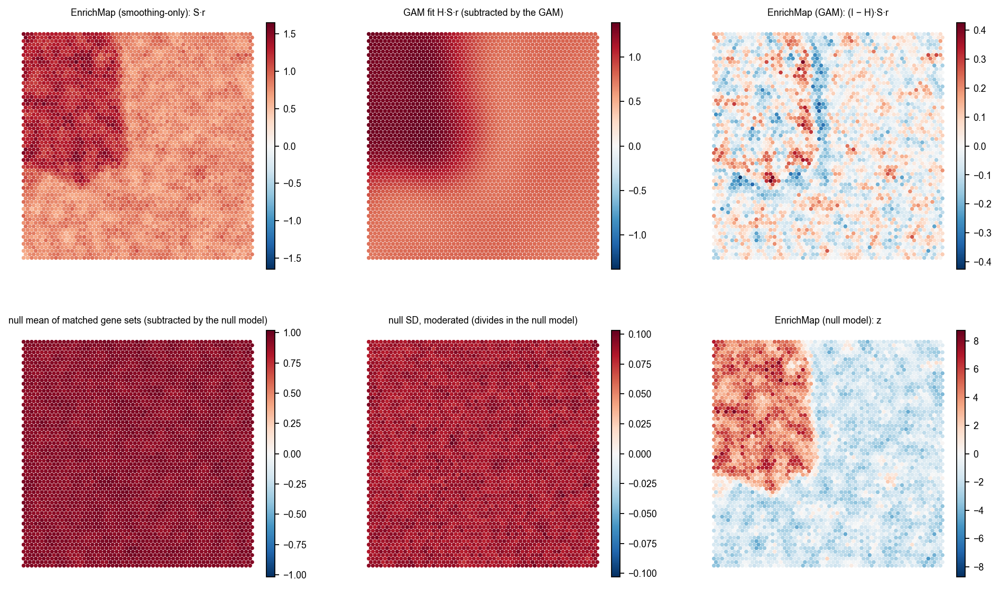

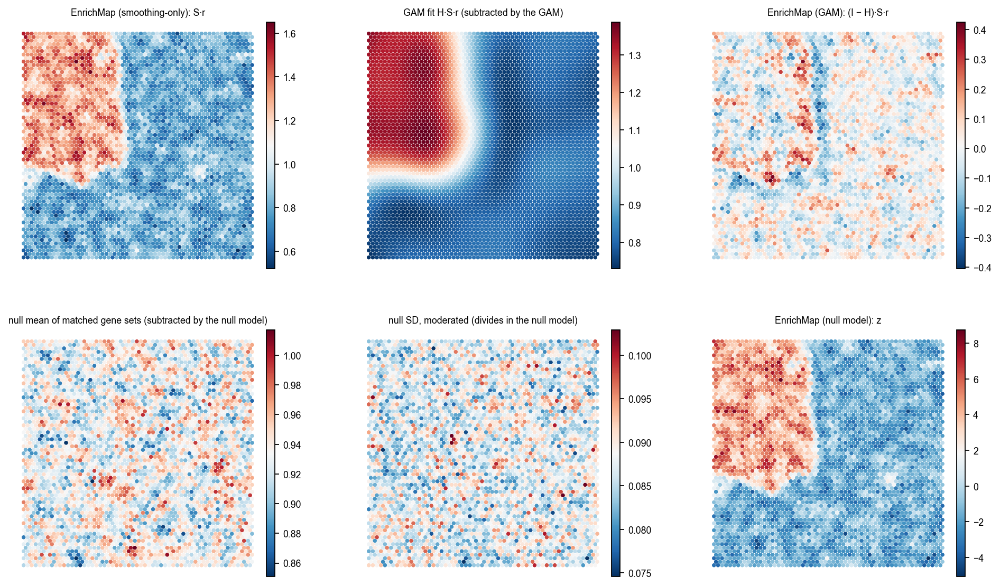

In [18]:
# 13. Mechanism maps, seed 0: what the GAM and the null model subtract (centred at 0 and uncentred)
mechanism_maps = {
    "EnrichMap (smoothing-only): S·r": sm0,
    "GAM fit H·S·r (subtracted by the GAM)": fit0,
    "EnrichMap (GAM): (I − H)·S·r": res0,
    "null mean of matched gene sets (subtracted by the null model)": null0["null_mean"],
    "null SD, moderated (divides in the null model)": null0["null_sd"],
    "EnrichMap (null model): z": null0["null"],
}
for key, v in mechanism_maps.items():
    adata_0.obs[key] = v
for vcenter, tag in ((0, "centred"), (None, "uncentred")):
    em.pl.spatial_enrichmap(
        adata_0,
        score_key=list(mechanism_maps),
        ncols=3,
        vcenter=vcenter,
        save=f"F2b_GAM_mechanism_maps_{tag}.pdf",
        shape=None,
        size=spot_size,
    )
pd.DataFrame({
    "spot": adata_0.obs_names, "x": xy0[:, 0], "y": xy0[:, 1], "target domain (truth)": y0.astype(int),
    "ring just outside target": edge0.astype(int), **mechanism_maps, "null-model p_empirical": null0["p_empirical"],
}).to_csv(source_dir + "F2b_GAM_mechanism_maps.csv", index=False)

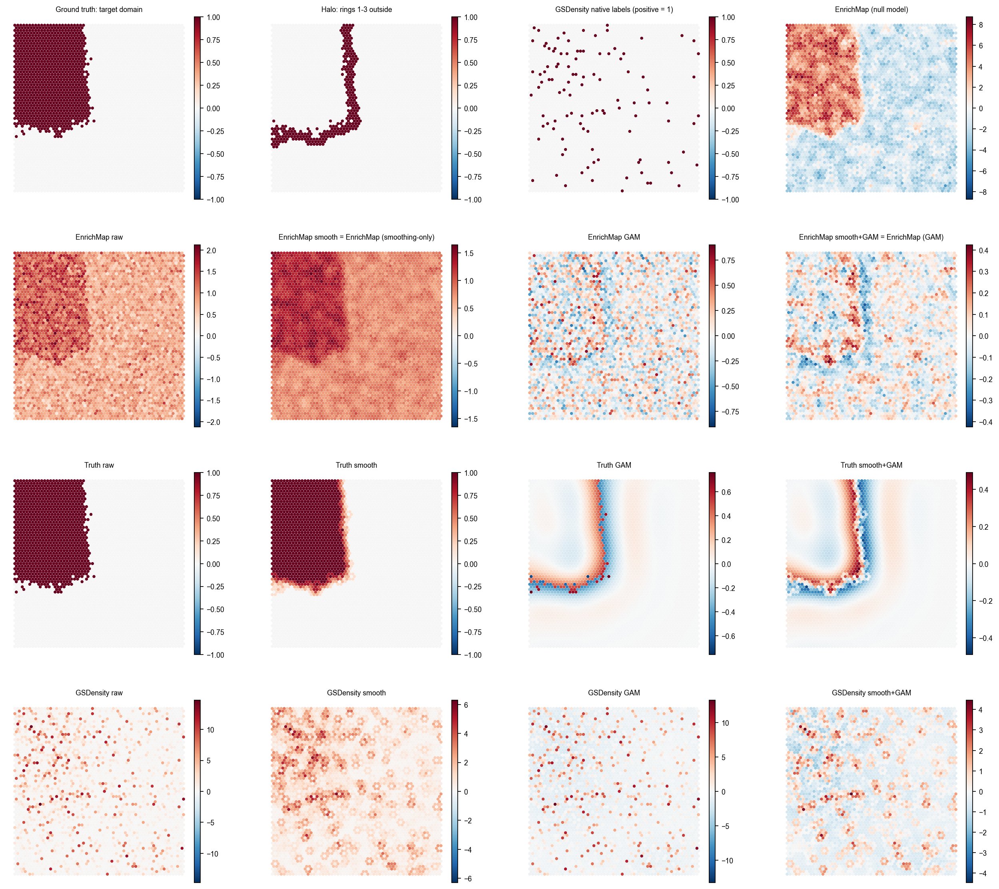

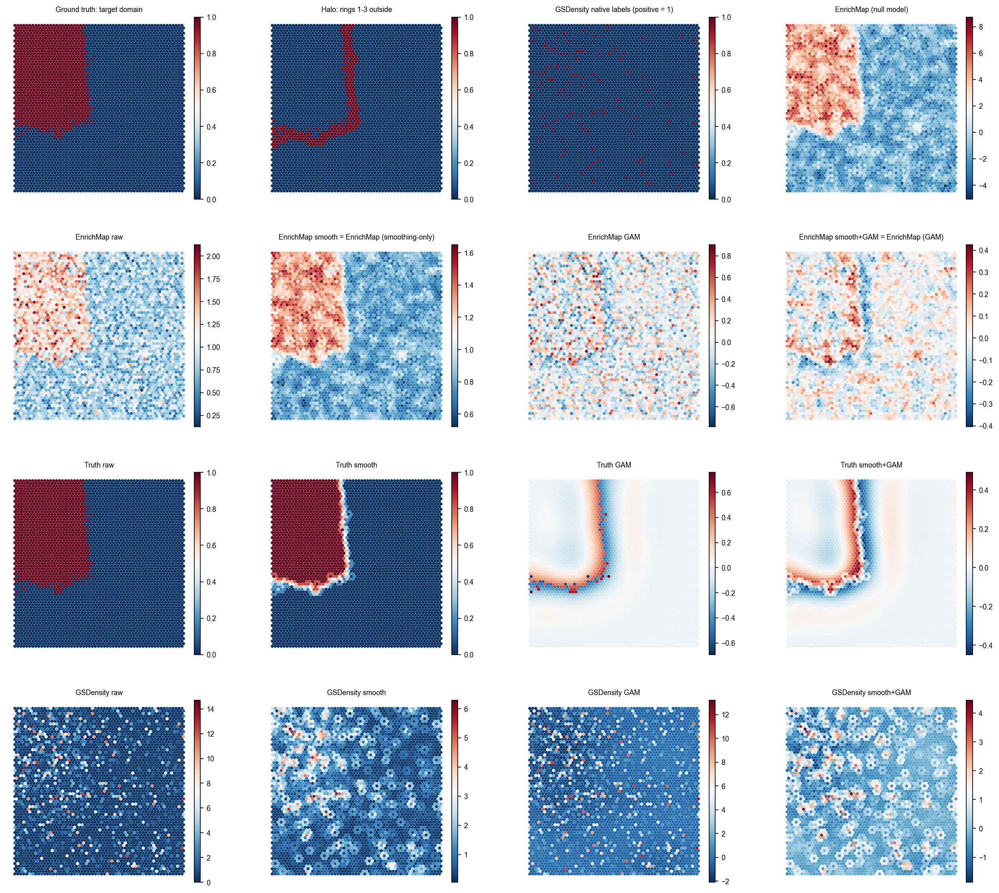

In [19]:
# 14. Example slide (seed 0) under each configuration: EnrichMap, the oracle truth and GSDensity
cf0 = dict(f2b_configurations(raw0, conn0, gam0), **{null_config: null0["null"]})
cft = f2b_configurations(y0, conn0, gam0)
gsd0 = np.load(f2b_dir + "gsd/seed000_scores.npz")["clean|GSDensity"].astype(np.float64)
cfg_gsd = f2b_configurations(gsd0, conn0, gam0)
gsd_label0 = pd.read_csv(gsd_dir + f"SupFig1_seed000_{target_0}.csv", index_col=0).loc[adata_0.obs_names, "label"]
halo0 = np.isin(dist0, [1, 2, 3])
example_maps = {
    "Ground truth: target domain": y0,
    "Halo: rings 1-3 outside": halo0.astype(float),
    "GSDensity native labels (positive = 1)": (gsd_label0 == "positive").values.astype(float),
    "EnrichMap (null model)": cf0[null_config],
    "EnrichMap raw": cf0["raw"],
    "EnrichMap smooth = EnrichMap (smoothing-only)": cf0["smooth"],
    "EnrichMap GAM": cf0["GAM"],
    "EnrichMap smooth+GAM = EnrichMap (GAM)": cf0["smooth+GAM"],
    **{f"Truth {cfg}": v for cfg, v in cft.items()},
    **{f"GSDensity {cfg}": v for cfg, v in cfg_gsd.items()},
}
for key, v in example_maps.items():
    adata_0.obs[key] = v
for vcenter, tag in ((0, "centred"), (None, "uncentred")):
    em.pl.spatial_enrichmap(
        adata_0,
        score_key=list(example_maps),
        ncols=4,
        vcenter=vcenter,
        save=f"F2b_example_slide_configs_{tag}.pdf",
        shape=None,
        size=spot_size,
    )
pd.DataFrame({"spot": adata_0.obs_names, "x": xy0[:, 0], "y": xy0[:, 1], **example_maps}).to_csv(
    source_dir + "F2b_example_slide_configs.csv", index=False,
)

Leakage: background spots are binned by graph distance (rings of 6-NN neighbours) to the target domain.
L(d) = (ring-d mean − mean ≥ 6 rings away) / (inside mean − mean ≥ 6 rings away), so L = 0 is no leakage and L = 1
means ring d scores like the domain; the halo leakage index is mean L over rings 1–3 (negative = a trough below
background). Ring means are also expressed in far-background SD units; region-vs-halo AUROC summarises boundary sharpness.

In [20]:
# 15. Leakage per slide, method and configuration
leak_metrics = [
    "halo leakage index", "region-vs-halo AUROC", "top-k share in halo", "top-k share inside",
    "inside contrast (far-background SD)", "halo rings 1-3 (far-background SD)", "min over rings 1-8 (far-background SD)",
]
lsum = leak.groupby(["method", "config"])[leak_metrics].agg(["mean", "std"])
print(lsum.round(3).reindex([(m, c) for m in methods for c in configs_all if (m, c) in lsum.index]).to_string())
pl = f2b_paired_table(
    leak.melt(id_vars=["seed", "method", "config"], var_name="metric", value_name="value"),
    leak_metrics, methods,
    {
        "smooth+GAM vs smooth": ("smooth", "smooth+GAM"), "GAM vs raw": ("raw", "GAM"), "smooth vs raw": ("raw", "smooth"),
        "null model vs smooth": ("smooth", null_config), "null model vs smooth+GAM": ("smooth+GAM", null_config),
    },
)
print(
    pl[pl.method.isin(["EnrichMap", "Truth (oracle)"])][
        ["metric", "method", "contrast", "n seeds", "mean without", "mean with", "mean diff", "wilcoxon p"]
    ].round(4).to_string()
)

                          halo leakage index          region-vs-halo AUROC        top-k share in halo        top-k share inside        inside contrast (far-background SD)         halo rings 1-3 (far-background SD)        min over rings 1-8 (far-background SD)       
                                        mean      std                 mean    std                mean    std               mean    std                                mean     std                               mean    std                                   mean    std
method         config                                                                                                                                                                                                                                                     
EnrichMap      raw                    -0.000    0.022                0.961  0.016               0.025  0.016              0.830  0.049                               2.977   0.328                     

                                     metric          method                  contrast  n seeds  mean without  mean with  mean diff  wilcoxon p
0                        halo leakage index       EnrichMap      smooth+GAM vs smooth      100        0.1428    -5.4182    -5.5611      0.0000
1                        halo leakage index       EnrichMap                GAM vs raw      100       -0.0004    -3.1289    -3.1285      0.0000
2                        halo leakage index       EnrichMap             smooth vs raw      100       -0.0004     0.1428     0.1433      0.0000
3                        halo leakage index       EnrichMap      null model vs smooth      100        0.1428     0.1430     0.0001      0.6036
4                        halo leakage index       EnrichMap  null model vs smooth+GAM      100       -5.4182     0.1430     5.5612      0.0000
23                       halo leakage index  Truth (oracle)      smooth+GAM vs smooth      100        0.1444    -5.0770    -5.2213      0.0000

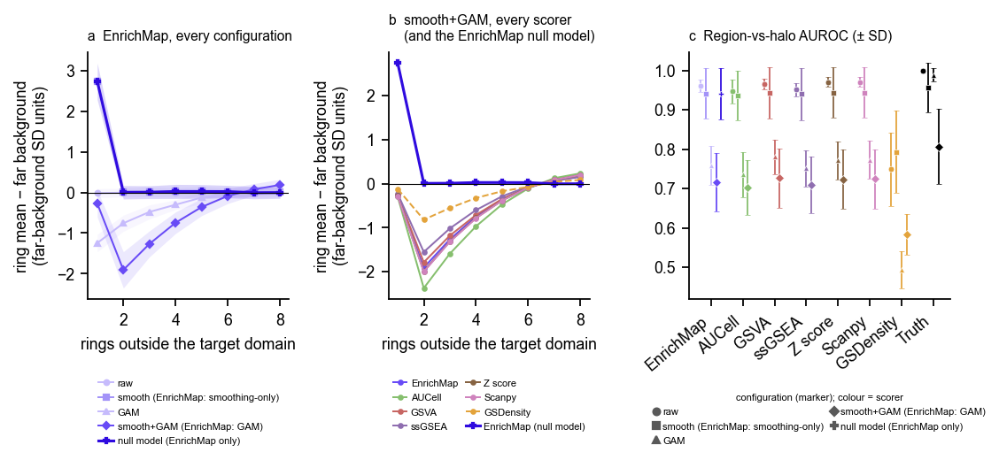

In [21]:
# 16. Leakage figure
psum = prof.groupby(["method", "config", "ring"]).z.agg(["mean", "std", "count"]).reset_index()
lmean = (
    leak.melt(id_vars=["seed", "method", "config"], var_name="metric", value_name="value")
    .groupby(["method", "config", "metric"]).value.agg(mean="mean", sd="std", n="count").reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(7.8, 3.3), gridspec_kw={"width_ratios": [1, 1, 1.3], "wspace": 0.45})
ax = axes[0]
for cfg in configs_all:
    s = psum[(psum.method == "EnrichMap") & (psum.config == cfg)]
    ax.plot(s.ring, s["mean"], marker=plot_style["markers"][cfg], ms=2.5, lw=1.4 if cfg == null_config else 0.9,
            color=em_colour[cfg], label=plot_style["config_labels"].get(cfg, cfg))
    ax.fill_between(s.ring, s["mean"] - s["std"], s["mean"] + s["std"], color=em_colour[cfg], alpha=0.12, lw=0)
ax.set_title("a  EnrichMap, every configuration", fontsize=7, loc="left")
ax = axes[1]
for m in scorers:
    s = psum[(psum.method == m) & (psum.config == "smooth+GAM")]
    ax.plot(s.ring, s["mean"], "--" if m == "GSDensity" else "-", marker="o", ms=2, lw=0.9,
            color=colours[plot_style["colour_key"][(m, "smooth+GAM")]], label=labels.get(m, m))
s = psum[(psum.method == "EnrichMap") & (psum.config == null_config)]
ax.plot(s.ring, s["mean"], marker=plot_style["markers"][null_config], ms=2.5, lw=1.4, color=em_colour[null_config],
        label="EnrichMap (null model)")
ax.set_title("b  smooth+GAM, every scorer\n    (and the EnrichMap null model)", fontsize=7, loc="left")
ax.legend(frameon=False, fontsize=5, handlelength=1.4, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2,
          columnspacing=0.8)
for ax in axes[:2]:
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("rings outside the target domain")
    ax.set_ylabel("ring mean − far background\n(far-background SD units)")
axes[0].legend(frameon=False, handlelength=1.5, fontsize=5, loc="upper center", bbox_to_anchor=(0.5, -0.3))
f2b_dotplot(axes[2], lmean, "region-vs-halo AUROC", methods, configs_all, plot_style, err="sd", title="")
axes[2].set_title("c  Region-vs-halo AUROC (± SD)", fontsize=7, loc="left")
axes[2].legend(handles=f2b_config_handles(configs_all, plot_style), title="configuration (marker); colour = scorer",
               title_fontsize=5, frameon=False, fontsize=5, loc="upper center", bbox_to_anchor=(0.5, -0.36), ncol=2,
               columnspacing=0.8)
for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)
fig.subplots_adjust(bottom=0.38)
plt.savefig(figure_dir + "F2b_leakage.pdf", bbox_inches="tight")
plt.show()

ring_em = psum[psum.method == "EnrichMap"].rename(columns={"std": "sd", "count": "n slides"})
ring_em = ring_em.assign(**{"band low": ring_em["mean"] - ring_em["sd"], "band high": ring_em["mean"] + ring_em["sd"]})
ring_sg = psum[(psum.method.isin(scorers) & (psum.config == "smooth+GAM"))
               | ((psum.method == "EnrichMap") & (psum.config == null_config))].rename(columns={"count": "n slides"})
pd.concat({
    "a": ring_em[["config", "ring", "n slides", "mean", "sd", "band low", "band high"]].reset_index(drop=True),
    "b": f2b_categorical_to_str(ring_sg[["method", "config", "ring", "n slides", "mean"]], labels),
    "c": f2b_dot_table(lmean, "region-vs-halo AUROC", methods, configs_all, labels, err="sd"),
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_leakage.csv", index=False)

In [22]:
# 17. Does smoothing alone explain EnrichMap's advantage in Sup. Fig. 1e? (and where does the null model stand?)
# original: EnrichMap smooth vs competitor raw; like-for-like: both smoothed. z-score is the unweighted EnrichMap,
# so EnrichMap-smooth vs z-score-smooth isolates the CV weights
competitors = [m for m in scorers if m != "EnrichMap"]
vse = []
for met in key_metrics:
    for cfg_em, cfg_other in [("smooth", "raw"), ("smooth", "smooth"), ("raw", "raw"), (null_config, "raw"),
                              (null_config, "smooth")]:
        vse += f2b_vs_enrichmap(clf, met, cfg_em, cfg_other, competitors)
vse = pd.DataFrame(vse)
vse["Δ (95% CI)"] = [
    f"{d:+.4f} [{lo:+.4f}, {hi:+.4f}] ({b:.0%})"
    for d, lo, hi, b in zip(vse["mean diff"], vse["95% CI low"], vse["95% CI high"], vse["frac EnrichMap better"])
]
kinds = vse.comparison.str.extract(r"EnrichMap\[([^\]]+)\] − .*\[([^\]]+)\]")
vse["kind"] = "EM " + kinds[0] + " vs other " + kinds[1]
for met in ["AUROC", "F1 (oracle threshold)", "F1 (top-k, prevalence-matched)", "Spatial coherence (top-k)", "Moran's I"]:
    print(f"\n=== {met}: EnrichMap minus competitor, mean [95% CI] (share of slides EnrichMap better) ===")
    print(vse[vse.metric == met].pivot_table(index="method", columns="kind", values="Δ (95% CI)", aggfunc="first").to_string())

# share of the original advantage that remains once the competitor is smoothed too
fr = []
for met in ["AUROC", "AUPRC", "F1 (oracle threshold)", "F1 (top-k, prevalence-matched)"]:
    for m in competitors:
        a = vse[(vse.metric == met) & (vse.method == m) & (vse.kind == "EM smooth vs other raw")]["mean diff"]
        b = vse[(vse.metric == met) & (vse.method == m) & (vse.kind == "EM smooth vs other smooth")]["mean diff"]
        if len(a) and len(b):
            fr.append({
                "metric": met, "method": m, "original gap (EM smooth − other raw)": a.iloc[0],
                "like-for-like gap (EM smooth − other smooth)": b.iloc[0],
                "share of gap explained by smoothing": 1 - b.iloc[0] / a.iloc[0],
            })
fr = pd.DataFrame(fr)
print("\n", fr.pivot_table(index="method", columns="metric", values="share of gap explained by smoothing").round(3).to_string())


=== AUROC: EnrichMap minus competitor, mean [95% CI] (share of slides EnrichMap better) ===
kind              EM null model vs other raw      EM null model vs other smooth                EM raw vs other raw             EM smooth vs other raw          EM smooth vs other smooth
method                                                                                                                                                                                  
AUCell      +0.0317 [+0.0216, +0.0417] (89%)   +0.0000 [-0.0008, +0.0009] (47%)   +0.0144 [+0.0092, +0.0196] (66%)   +0.0317 [+0.0217, +0.0417] (89%)   +0.0001 [-0.0008, +0.0009] (47%)
GSDensity  +0.2305 [+0.2130, +0.2480] (100%)  +0.1346 [+0.1158, +0.1534] (100%)  +0.2132 [+0.1960, +0.2304] (100%)  +0.2305 [+0.2130, +0.2481] (100%)  +0.1347 [+0.1159, +0.1535] (100%)
GSVA        +0.0126 [+0.0045, +0.0206] (84%)   -0.0001 [-0.0005, +0.0004] (36%)   -0.0047 [-0.0062, -0.0033] (28%)   +0.0126 [+0.0046, +0.0206] (84%)   -0.0000 [-0.000

Neighbourhood concordance (Sup. Fig. 1a): as implemented, the ground-truth labels are smoothed k times and correlated
(Spearman) with the unchanged score; the Methods text describes the reverse (scores smoothed, correlated with the
binary labels). Both are shown.

In [23]:
# 18. Concordance summary
csum = conc.groupby(["variant", "method", "config", "k"]).rho.agg(["mean", "std", "count"]).reset_index()
for var in csum.variant.unique():
    t = csum[(csum.variant == var) & (csum.method.isin(methods)) & (csum.config.isin(configs_all))]
    t = t.assign(v=[f"{a:.3f}±{b:.3f}" for a, b in zip(t["mean"], t["std"])]).pivot_table(
        index=["method", "config"], columns="k", values="v", aggfunc="first",
    )
    print(f"\n=== {var} (mean ± SD over slides) ===")
    print(t.reindex([(m, c) for m in methods for c in configs_all if (m, c) in t.index]).to_string())

# concordance area per slide: mean rho over k = 1, 3, 5, 7, 10
conc_variants = ["labels smoothed (as implemented)", "scores smoothed (Methods text)"]
conc_short = {conc_variants[0]: "Concordance, labels smoothed", conc_variants[1]: "Concordance, scores smoothed"}
conc_area = (
    conc[conc.variant.isin(conc_variants)].groupby(["method", "config", "seed", "variant"]).rho.mean()
    .unstack("variant").rename(columns=conc_short).reset_index()
)
conc_tab = f2b_mean_ci(
    conc_area[conc_area.method.isin(methods) & conc_area.config.isin(configs_all)], list(conc_short.values()),
    method_order, config_order,
)
print(conc_tab[["method", "config"] + list(conc_short.values())].round(3).to_string(index=False))


=== labels smoothed (as implemented) (mean ± SD over slides) ===
k                                    1             3             5             7             10
method         config                                                                          
EnrichMap      raw          0.609±0.112   0.580±0.111   0.557±0.112   0.540±0.113   0.522±0.114
               smooth       0.763±0.080   0.714±0.094   0.686±0.099   0.665±0.102   0.643±0.107
               GAM          0.039±0.019  -0.004±0.012  -0.018±0.012  -0.019±0.011  -0.012±0.009
               smooth+GAM   0.122±0.044   0.007±0.025  -0.029±0.023  -0.031±0.019  -0.017±0.015
               null model   0.763±0.080   0.714±0.094   0.686±0.099   0.665±0.103   0.642±0.107
AUCell         raw          0.600±0.114   0.572±0.113   0.549±0.114   0.532±0.114   0.514±0.114
               smooth       0.766±0.079   0.717±0.092   0.687±0.098   0.667±0.100   0.644±0.105
               GAM          0.011±0.032  -0.039±0.031  -0.058±0.035  -

        method     config  Concordance, labels smoothed  Concordance, scores smoothed
     EnrichMap        raw                         0.562                         0.718
     EnrichMap     smooth                         0.694                         0.723
     EnrichMap        GAM                        -0.003                         0.179
     EnrichMap smooth+GAM                         0.010                         0.204
     EnrichMap null model                         0.694                         0.723
        AUCell        raw                         0.553                         0.718
        AUCell     smooth                         0.696                         0.723
        AUCell        GAM                        -0.038                         0.176
        AUCell smooth+GAM                        -0.003                         0.204
          GSVA        raw                         0.568                         0.718
          GSVA     smooth                         0.69

                            labels sm., mean over k  scores sm., mean over k  labels sm., k = 1  labels sm., k = 10
label                                                                                                              
EnrichMap (null model)                        0.694                    0.723              0.763               0.642
EnrichMap (smoothing-only)                    0.694                    0.723              0.763               0.643
EnrichMap (GAM)                               0.010                    0.204              0.122              -0.017
AUCell                                        0.553                    0.718              0.600               0.514
GSVA                                          0.568                    0.718              0.616               0.528
ssGSEA                                        0.550                    0.717              0.596               0.511
Z score                                       0.574                    0

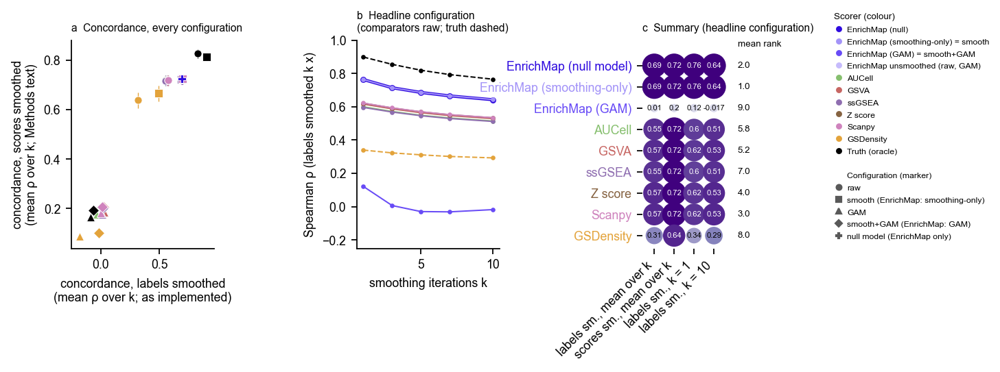

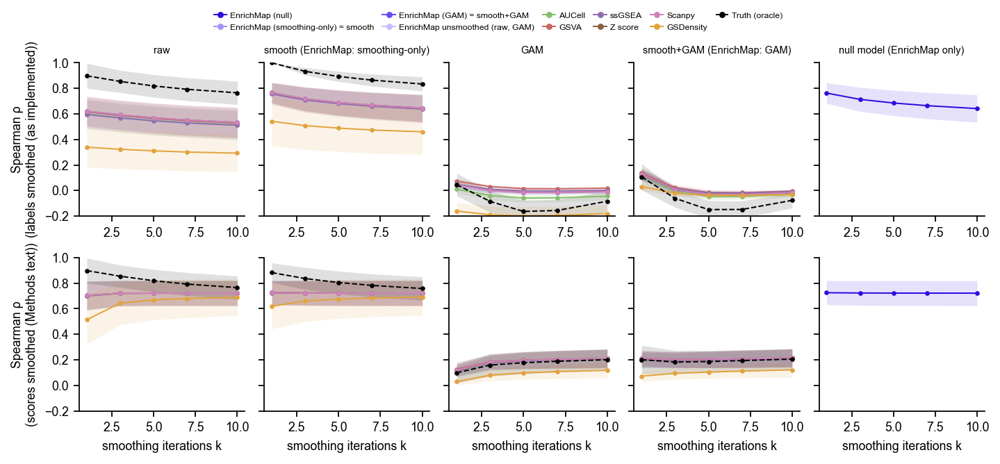

In [24]:
# 19. Concordance figures: compact (area pair + headline curves) and full (every configuration)
ck = csum[csum.variant == conc_variants[0]].pivot_table(index=["method", "config"], columns="k", values="mean")
conc_summary = f2b_headline_table(
    conc_tab.merge(ck[[1, 10]].rename(columns={1: "k1", 10: "k10"}).reset_index(), on=["method", "config"]),
    {"Concordance, labels smoothed": "labels sm., mean over k", "Concordance, scores smoothed": "scores sm., mean over k",
     "k1": "labels sm., k = 1", "k10": "labels sm., k = 10"},
    headline,
)
print(conc_summary.round(3).to_string())

fig, axes, ax_c, lax = f2b_compact_layout()
conc_a = f2b_factorial_pair(axes[0], conc_tab, *conc_short.values(), methods, configs_all, plot_style)
axes[0].set_xlabel("concordance, labels smoothed\n(mean ρ over k; as implemented)")
axes[0].set_ylabel("concordance, scores smoothed\n(mean ρ over k; Methods text)")
axes[0].set_title("a  Concordance, every configuration", fontsize=7, loc="left")
conc_b = f2b_headline_curves(axes[1], csum[csum.variant == conc_variants[0]], "k", "Spearman ρ (labels smoothed k x)",
                             "smoothing iterations k", headline, colours, null_config, ylim=(-0.25, 1.0))
axes[1].set_title("b  Headline configuration\n(comparators raw; truth dashed)", fontsize=7, loc="left")
f2b_plot_benchmark_summary(conc_summary, ax_c, colours)
ax_c.set_title("c  Summary (headline configuration)", fontsize=7, loc="left")
f2b_legend(lax, methods, configs_all, plot_style, bbox=(0.0, 1.15))
plt.savefig(figure_dir + "F2b_concordance_factorial.pdf", bbox_inches="tight")
plt.show()

pd.concat({
    "a": conc_a,
    "b": f2b_categorical_to_str(conc_b, labels),
    "c": conc_summary.reset_index().rename(columns={"label": "method"}),
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_concordance_factorial.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(9.0, 3.9), sharey="row")
for row, var in enumerate(conc_variants):
    f2b_lineplot_by_config(
        axes[row], csum[csum.variant == var], "k", methods, configs_all, plot_style, f"Spearman ρ\n({var})",
        "smoothing iterations k", ylim=(-0.2, 1.0), titles=(row == 0), xlabels=(row == 1),
    )
fig.legend(handles=f2b_method_handles(methods, configs_all, plot_style, kind="line"), loc="upper center", ncol=6,
           frameon=False, fontsize=5.5, bbox_to_anchor=(0.5, 1.06), handlelength=1.5)
for ax in axes.ravel():
    ax.grid(False)
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(figure_dir + "F2b_concordance_factorial_full.pdf", bbox_inches="tight")
plt.show()

pd.concat({
    chr(97 + 5 * row + j): f2b_line_table(csum[csum.variant == var], "k", methods, cfg, "count", labels).assign(variant=var)
    for row, var in enumerate(conc_variants) for j, cfg in enumerate(configs_all)
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_concordance_factorial_full.csv", index=False)

Contamination and noise (Sup. Fig. 1b,c): self-consistency = Spearman(clean, perturbed) of the same configuration (the
original metric); accuracy = AUROC of the perturbed score against the truth. The three repeats are averaged per slide,
then summarised over slides; compact panels summarise each curve by its area (mean over the perturbed levels per slide,
complete slides only). Slow scorers ran on fewer slides, so a second table restricts every scorer to the shared slides.

In [25]:
# 20. Robustness summaries
ps_c, rob_c = f2b_robustness_summary(contam)
ps_n, rob_n = f2b_robustness_summary(noise)

f2b_show_robustness(rob_c, "rho_self", "contamination: self-consistency ρ (mean±SD over slides)", [0.5, 1.0, 2.0, 4.0],
                    scorers, configs_all)
f2b_show_robustness(rob_c, "auroc", "contamination: AUROC vs truth", [0.0, 1.0, 4.0], scorers, configs_all)
f2b_show_robustness(rob_n, "rho_self", "noise: self-consistency ρ", [0.5, 1.0, 2.0, 3.0], scorers, configs_all)
f2b_show_robustness(rob_n, "auroc", "noise: AUROC vs truth", [0.0, 1.0, 3.0], scorers, configs_all)

# like-for-like on shared slides
for name, ps in [("contamination", ps_c), ("noise", ps_n)]:
    shared = set.intersection(*[set(ps[ps.method == m].seed) for m in scorers if m in set(ps.method)])
    sub = ps[ps.seed.isin(shared) & ps.method.isin(scorers) & ps.config.isin(["raw", "smooth", "smooth+GAM", null_config])]
    sub = sub[sub.level.isin([1.0, 4.0 if name == "contamination" else 3.0])]
    t = sub.groupby(["method", "config", "level"])[["rho_self", "auroc"]].mean().unstack("level").round(3)
    print(f"\n=== {name}: shared slides only (n = {len(shared)}) ===")
    print(t.to_string())

# robustness areas per slide: mean over the perturbed levels (> 0), slides with every level only
rob_names = {
    "Contamination robustness (ρ)": (ps_c, "rho_self"), "Noise robustness (ρ)": (ps_n, "rho_self"),
    "Contamination accuracy (AUROC)": (ps_c, "auroc"), "Noise accuracy (AUROC)": (ps_n, "auroc"),
}
area = pd.concat({k: f2b_robustness_area(ps, v) for k, (ps, v) in rob_names.items()}, axis=1).reset_index()
rob_tab = f2b_mean_ci(area[area.method.isin(scorers) & area.config.isin(configs_all)], list(rob_names), method_order,
                      config_order)
print(rob_tab[["method", "config"] + [c for k in rob_names for c in (k, f"{k} (n slides)")]].round(3).to_string(index=False))


=== contamination: self-consistency ρ (mean±SD over slides) ===
level                         0.5          1.0          2.0          4.0
method    config                                                        
EnrichMap raw         0.883±0.020  0.806±0.031  0.702±0.036  0.576±0.033
          smooth      0.914±0.024  0.864±0.040  0.803±0.055  0.725±0.063
          GAM         0.829±0.019  0.727±0.024  0.605±0.025  0.481±0.022
          smooth+GAM  0.846±0.018  0.751±0.025  0.632±0.026  0.507±0.027
          null model  0.910±0.025  0.858±0.042  0.797±0.057  0.721±0.068
AUCell    raw         0.898±0.056  0.822±0.085  0.742±0.093  0.628±0.098
          smooth      0.925±0.043  0.874±0.063  0.820±0.074  0.748±0.088
          GAM         0.872±0.061  0.776±0.089  0.673±0.093  0.537±0.084
          smooth+GAM  0.889±0.052  0.804±0.077  0.708±0.083  0.574±0.081
GSVA      raw         0.881±0.027  0.805±0.038  0.705±0.046  0.580±0.049
          smooth      0.910±0.028  0.859±0.042  0.799±0.058

   method     config  Contamination robustness (ρ)  Contamination robustness (ρ) (n slides)  Noise robustness (ρ)  Noise robustness (ρ) (n slides)  Contamination accuracy (AUROC)  Contamination accuracy (AUROC) (n slides)  Noise accuracy (AUROC)  Noise accuracy (AUROC) (n slides)
EnrichMap        raw                         0.742                                      100                 0.673                              100                           0.864                                        100                   0.839                                100
EnrichMap     smooth                         0.827                                      100                 0.778                              100                           0.957                                        100                   0.940                                100
EnrichMap        GAM                         0.660                                      100                 0.591                              100           

                            Contam. robustness (ρ)  Noise robustness (ρ)  Contam. accuracy (AUROC)  Noise accuracy (AUROC)
label                                                                                                                     
EnrichMap (null model)                       0.822                 0.773                     0.961                   0.940
EnrichMap (smoothing-only)                   0.827                 0.778                     0.957                   0.940
EnrichMap (GAM)                              0.684                 0.616                     0.559                   0.555
AUCell                                       0.772                 0.528                     0.889                   0.820
GSVA                                         0.743                 0.622                     0.882                   0.819
ssGSEA                                       0.743                 0.636                     0.858                   0.840
Z score         

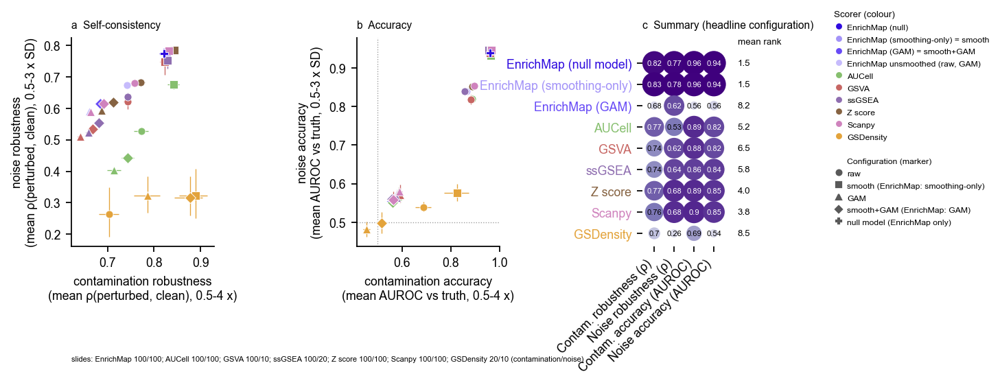

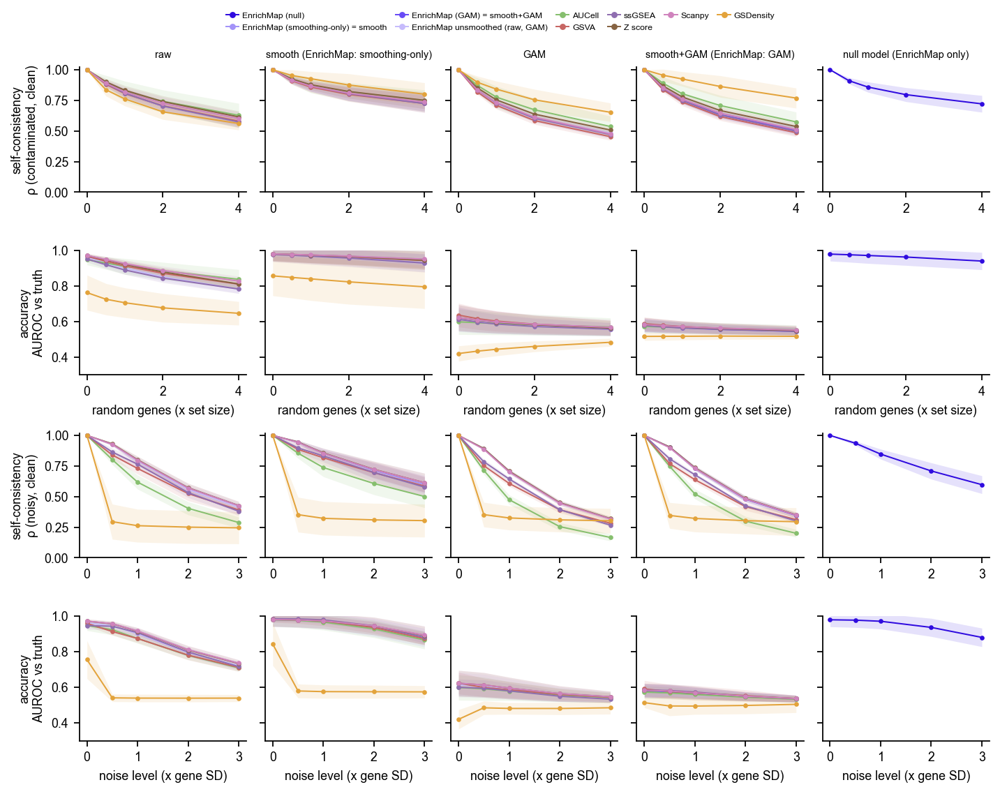

In [26]:
# 21. Robustness figures: compact (area pairs) and full (every curve)
rob_summary_tab = f2b_headline_table(rob_tab, {
    "Contamination robustness (ρ)": "Contam. robustness (ρ)", "Noise robustness (ρ)": "Noise robustness (ρ)",
    "Contamination accuracy (AUROC)": "Contam. accuracy (AUROC)", "Noise accuracy (AUROC)": "Noise accuracy (AUROC)",
}, headline)
print(rob_summary_tab.round(3).to_string())

fig, axes, ax_c, lax = f2b_compact_layout()
rob_a = f2b_factorial_pair(axes[0], rob_tab, "Contamination robustness (ρ)", "Noise robustness (ρ)", scorers,
                           configs_all, plot_style)
axes[0].set_xlabel("contamination robustness\n(mean ρ(perturbed, clean), 0.5-4 x)")
axes[0].set_ylabel("noise robustness\n(mean ρ(perturbed, clean), 0.5-3 x SD)")
axes[0].set_title("a  Self-consistency", fontsize=7, loc="left")
rob_b = f2b_factorial_pair(axes[1], rob_tab, "Contamination accuracy (AUROC)", "Noise accuracy (AUROC)", scorers,
                           configs_all, plot_style, ref_x=0.5, ref_y=0.5)
axes[1].set_xlabel("contamination accuracy\n(mean AUROC vs truth, 0.5-4 x)")
axes[1].set_ylabel("noise accuracy\n(mean AUROC vs truth, 0.5-3 x SD)")
axes[1].set_title("b  Accuracy", fontsize=7, loc="left")
f2b_plot_benchmark_summary(rob_summary_tab, ax_c, colours)
ax_c.set_title("c  Summary (headline configuration)", fontsize=7, loc="left")
f2b_legend(lax, scorers, configs_all, plot_style, bbox=(0.0, 1.15))
n_note = rob_tab.groupby("method")[[f"{k} (n slides)" for k in rob_names]].max()
axes[0].text(0.0, -0.55, "slides: " + "; ".join(
    f"{labels.get(m, m)} {int(r.iloc[0])}/{int(r.iloc[1])}" for m, r in n_note.reindex(scorers).iterrows()
) + " (contamination/noise)", transform=axes[0].transAxes, fontsize=5)
plt.savefig(figure_dir + "F2b_robustness_factorial.pdf", bbox_inches="tight")
plt.show()

pd.concat({
    "a": rob_a,
    "b": rob_b,
    "c": rob_summary_tab.reset_index().rename(columns={"label": "method"}),
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_robustness_factorial.csv", index=False)

rob_rows = [
    (rob_c, "rho_self", "self-consistency\nρ (contaminated, clean)", "random genes (x set size)", (0, 1.02)),
    (rob_c, "auroc", "accuracy\nAUROC vs truth", "random genes (x set size)", (0.3, 1.0)),
    (rob_n, "rho_self", "self-consistency\nρ (noisy, clean)", "noise level (x gene SD)", (0, 1.02)),
    (rob_n, "auroc", "accuracy\nAUROC vs truth", "noise level (x gene SD)", (0.3, 1.0)),
]
fig, axes = plt.subplots(4, 5, figsize=(9.0, 6.8), sharey="row")
for row, (rob, val, ylab, xlab, ylim) in enumerate(rob_rows):
    f2b_lineplot_by_config(
        axes[row], rob.rename(columns={f"{val}_mean": "mean", f"{val}_std": "std"}), "level", scorers, configs_all,
        plot_style, ylab, xlab, ylim=ylim, titles=(row == 0), xlabels=(row in (1, 3)),
    )
fig.legend(handles=f2b_method_handles(scorers, configs_all, plot_style, kind="line"), loc="upper center", ncol=6,
           frameon=False, fontsize=5.5, bbox_to_anchor=(0.5, 1.04), handlelength=1.5)
for ax in axes.ravel():
    ax.grid(False)
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(figure_dir + "F2b_robustness_factorial_full.pdf", bbox_inches="tight")
plt.show()

rob_titles = ["contamination self-consistency", "contamination accuracy", "noise self-consistency", "noise accuracy"]
pd.concat({
    chr(97 + 5 * row + j): f2b_line_table(
        rob.rename(columns={f"{val}_mean": "mean", f"{val}_std": "std"}), "level", scorers, cfg, f"{val}_count", labels,
    ).assign(measure=title)
    for row, ((rob, val, *_), title) in enumerate(zip(rob_rows, rob_titles)) for j, cfg in enumerate(configs_all)
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_robustness_factorial_full.csv", index=False)

GSDensity returns a random-walk-with-restart probability p over spots (non-negative, sums to one, coordinate-free).
The operators are applied to n·p (a positive rescaling that leaves every metric unchanged), with log1p(n·p) as a
sensitivity transform. Slides 0–19 were also scored with `dims 1:30`, `dims 1:50`, `restart 0.5` and `nn.use 100`.

In [27]:
# 22. GSDensity: parameter sensitivity, native outputs and pathway-level spatial relevance (compute.spatial.kld)
par = clf[clf.method.str.startswith("GSDensity") & clf.metric.isin(
    ["AUROC", "AUPRC", "F1 (top-k, prevalence-matched)", "F1 (oracle threshold)"])].copy()
par["setting"] = par.method.str.extract(r"\[(.*)\]")[0].fillna("default")
par["tf"] = np.where(par.method.str.contains("log1p"), "log1p(n·p)", "n·p")
pseeds = sorted(par[par.setting != "default"].seed.unique())
par = par[par.seed.isin(pseeds)]
pt_g = par.groupby(["tf", "setting", "config", "metric"])["value"].agg(["mean", "std", "count"]).reset_index()
pt_g.to_csv(working_dir + "data/F2b/F2b_gsdensity_parameter_sensitivity.csv", index=False)
print(f"slides in the sensitivity arm: n = {len(pseeds)}")
t = pt_g[pt_g["tf"] == "n·p"].copy()
t["v"] = t["mean"].round(3).astype(str) + "±" + t["std"].round(3).astype(str)
print(t.pivot_table(index=["setting", "config"], columns="metric", values="v", aggfunc="first").to_string())
best = pt_g[(pt_g["tf"] == "n·p") & (pt_g.config == "raw") & (pt_g.metric == "AUROC")].sort_values("mean", ascending=False)
print(
    f"\nbest setting by mean raw AUROC: {best.iloc[0]['setting']} {best.iloc[0]['mean']:.3f} | "
    f"default: {best[best.setting == 'default']['mean'].iloc[0]:.3f}"
)

# EnrichMap on the same slides
em_same = clf[(clf.method == "EnrichMap") & clf.seed.isin(pseeds) & (clf.metric == "AUROC")].groupby("config")["value"].agg(["mean", "std"])
print("EnrichMap AUROC on the same slides:\n", em_same.round(3).to_string())
g0 = gsd.groupby("setting")[["native_label_F1", "native_frac_positive", "frac_zero"]].agg(["mean", "std", "count"]).round(3)
print("\nGSDensity native binarisation (compute.cell.label) and zero inflation:\n", g0.to_string())

# pathway-level spatial relevance: target sets, random 20-gene sets and contaminated sets (permutation p)
kld["set_type"] = np.where(
    kld["set"] == "target", "target",
    np.where(kld["set"] == "random", "random 20 genes",
             "contaminated " + kld["set"].str.extract(r"c([\d.]+)_")[0].fillna("") + "x"),
)
ks = kld.groupby("set_type").agg(
    n=("p.value", "size"), median_p=("p.value", "median"), frac_p_lt_0_05=("p.value", lambda v: (v < 0.05).mean()),
    frac_padj_lt_0_05=("p.adj", lambda v: (v < 0.05).mean()), median_delta_kld=("delta.kld", "median"),
)
print(ks.round(4).to_string())
ks.to_csv(working_dir + "data/F2b/F2b_gsdensity_spatial_kld_summary.csv")


slides in the sensitivity arm: n = 20
metric                       AUPRC        AUROC F1 (oracle threshold) F1 (top-k, prevalence-matched)
setting    config                                                                                   
default    GAM         0.334±0.131   0.42±0.043            0.426±0.12                    0.351±0.087
           raw         0.534±0.218  0.762±0.098           0.551±0.166                    0.511±0.185
           smooth        0.7±0.243  0.856±0.112           0.669±0.199                    0.652±0.216
           smooth+GAM  0.368±0.145  0.516±0.023           0.416±0.122                    0.363±0.112
dims30     GAM         0.391±0.136  0.494±0.043           0.454±0.116                    0.402±0.092
           raw         0.631±0.203  0.808±0.082           0.602±0.152                    0.588±0.158
           smooth      0.833±0.187  0.929±0.068            0.79±0.165                    0.784±0.168
           smooth+GAM  0.409±0.141  0.542±0.021      

Sup. Fig. 1d gene weights: `run_gene_weight_validation` correlated mean |expression × CV weight| with the true fold
change; for non-negative expression mean|x·w| = w·mean(x) = SD, so the panel measured Spearman(gene SD, FC), not
Spearman(CV weight, FC). Both are computed per slide; the weighting arm is repeated under the null model.

In [28]:
# 23. Gene weights per slide and weighting schemes
gws = []
for seed, d in gw.groupby("seed"):
    gws.append({
        "seed": seed,
        "rho(CV weight, true FC)": stats.spearmanr(d.cv_weight, d.true_fc).correlation,
        "rho(mean|contribution|, true FC) [original panel]": stats.spearmanr(d.mean_abs_contribution, d.true_fc).correlation,
        "rho(SD, true FC)": stats.spearmanr(d.sd, d.true_fc).correlation,
        "rho(empirical Δlog-expr, true FC)": stats.spearmanr(d.empirical_dlog, d.true_fc).correlation,
        "rho(CV weight, background mean)": stats.spearmanr(d.cv_weight, d.background_mean).correlation,
        "rho(CV weight, gene AUROC)": stats.spearmanr(d.cv_weight, d.gene_auroc).correlation,
        "rho(SD, gene AUROC)": stats.spearmanr(d.sd, d.gene_auroc).correlation,
        "max |mean|contribution| - SD|": float(np.max(np.abs(d.mean_abs_contribution - d.sd))),
    })
gws = pd.DataFrame(gws).set_index("seed")
gsumm = gws.agg(["median", "mean", "std", "min", "max"]).T
gsumm["frac > 0"] = (gws > 0).mean()
print(gsumm.round(3).to_string())
dd = gws["rho(CV weight, true FC)"] - gws["rho(mean|contribution|, true FC) [original panel]"]
print(f"\npaired difference CV-metric minus original metric: median {dd.median():.3f}, "
      f"Wilcoxon p = {stats.wilcoxon(dd).pvalue:.2e}, n = {len(dd)}")

# partial Spearman(CV weight, true FC | background mean), rank regression per slide
pc = []
for seed, d in gw.groupby("seed"):
    X = np.column_stack([np.ones(len(d)), stats.rankdata(d.background_mean)])
    res_cv = stats.rankdata(d.cv_weight) - X @ np.linalg.lstsq(X, stats.rankdata(d.cv_weight), rcond=None)[0]
    res_fc = stats.rankdata(d.true_fc) - X @ np.linalg.lstsq(X, stats.rankdata(d.true_fc), rcond=None)[0]
    pc.append(np.corrcoef(res_cv, res_fc)[0, 1])
print(f"partial Spearman(CV weight, true FC | background mean): median {np.median(pc):.3f}, "
      f"frac > 0: {np.mean(np.array(pc) > 0):.3f}")

# does the weighting matter for classification? (paired over slides; uniform weights = z-score for raw / smooth)
weight_alts = {
    "uniform weights": {"raw": "z-score", "smooth": "z-score", null_config: "EnrichMap (uniform weights)"},
    "SD weights": {c: "EnrichMap (SD weights)" for c in ["raw", "smooth", null_config]},
    "oracle log-FC weights": {c: "EnrichMap (oracle log-FC weights)" for c in ["raw", "smooth", null_config]},
}
wt = []
for cfg in ["raw", "smooth", null_config]:
    piv = clf[(clf.metric == "AUROC") & (clf.config == cfg)].pivot_table(index="seed", columns="method", values="value")
    for w_name, by_cfg in weight_alts.items():
        m = by_cfg[cfg]
        d = (piv[m] - piv["EnrichMap"]).dropna()
        wt.append({
            "config": cfg, "weighting vs CV weights": w_name, "scorer": m, "n": len(d),
            "mean AUROC CV": piv["EnrichMap"][d.index].mean(), "mean AUROC alt": piv[m][d.index].mean(),
            "mean diff (alt − CV)": d.mean(), "frac alt better": (d > 0).mean(), "wilcoxon p": stats.wilcoxon(d).pvalue,
        })
wt = pd.DataFrame(wt)
print("\n", wt.round(4).to_string())

                                                   median   mean    std    min    max  frac > 0
rho(CV weight, true FC)                            -0.100 -0.075  0.225 -0.547  0.507      0.36
rho(mean|contribution|, true FC) [original panel]   0.243  0.204  0.221 -0.429  0.672      0.83
rho(SD, true FC)                                    0.243  0.204  0.221 -0.429  0.672      0.83
rho(empirical Δlog-expr, true FC)                   0.705  0.681  0.132  0.202  0.923      1.00
rho(CV weight, background mean)                    -0.938 -0.928  0.041 -0.985 -0.811      0.00
rho(CV weight, gene AUROC)                         -0.621 -0.619  0.153 -0.889 -0.044      0.00
rho(SD, gene AUROC)                                 0.409  0.377  0.211 -0.174  0.786      0.94
max |mean|contribution| - SD|                       0.000  0.000  0.000  0.000  0.000      1.00

paired difference CV-metric minus original metric: median -0.313, Wilcoxon p = 2.26e-08, n = 100
partial Spearman(CV weight, true FC | 

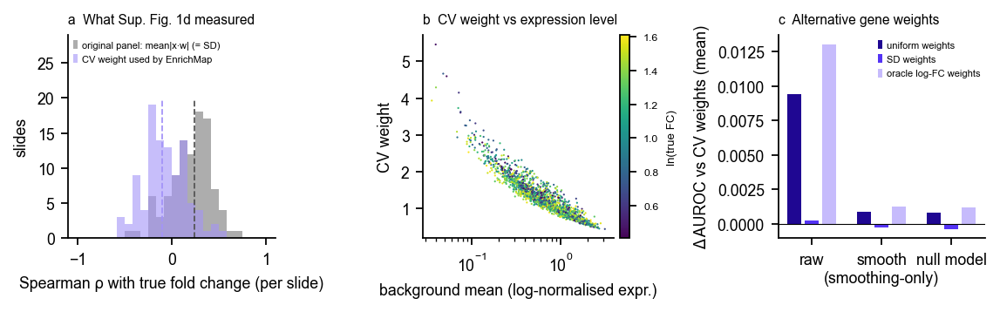

In [29]:
# 24. Gene-weight figure (Sup. Fig. 1d)
weight_cfgs = ["raw", "smooth", null_config]
rho_cols = ["rho(mean|contribution|, true FC) [original panel]", "rho(CV weight, true FC)"]
bins = np.linspace(-1, 1, 25)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3))
ax = axes[0]
ax.hist(gws[rho_cols[0]], bins=bins, color="#999999", alpha=0.8, label="original panel: mean|x·w| (= SD)")
ax.hist(gws[rho_cols[1]], bins=bins, color=colours["EnrichMap (smoothing-only)"], alpha=0.6,
        label="CV weight used by EnrichMap")
for c_, v in [("#555555", gws[rho_cols[0]].median()), (colours["EnrichMap (smoothing-only)"], gws[rho_cols[1]].median())]:
    ax.axvline(v, ymax=1 / 1.45, color=c_, ls="--", lw=0.8)  # median lines stop below the legend
ax.set_xlabel("Spearman ρ with true fold change (per slide)")
ax.set_ylabel("slides")
ax.set_ylim(0, ax.get_ylim()[1] * 1.45)
ax.legend(frameon=False, fontsize=5, loc="upper left")
ax.set_title("a  What Sup. Fig. 1d measured", fontsize=7, loc="left")
ax = axes[1]
pts = ax.scatter(gw.background_mean, gw.cv_weight, s=1, c=np.log(gw.true_fc), cmap="viridis", lw=0)
cb = fig.colorbar(pts, ax=ax, fraction=0.05, pad=0.03)
cb.set_label("ln(true FC)", fontsize=6)
cb.ax.tick_params(labelsize=5.5)
ax.set_xscale("log")
ax.set_xlabel("background mean (log-normalised expr.)")
ax.set_ylabel("CV weight")
ax.set_title("b  CV weight vs expression level", fontsize=7, loc="left")
ax = axes[2]
for i, (w_name, col) in enumerate(weight_colours.items()):
    for j, cfg in enumerate(weight_cfgs):
        r = wt[(wt.config == cfg) & (wt["weighting vs CV weights"] == w_name)]
        ax.bar(j * 4 + i, r["mean diff (alt − CV)"].iloc[0], color=col, label=w_name if j == 0 else None)
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks([1, 5, 9])
ax.set_xticklabels(["raw", "smooth\n(smoothing-only)", "null model"])
ax.set_ylabel("Δ AUROC vs CV weights (mean)")
ax.set_title("c  Alternative gene weights", fontsize=7, loc="left")
ax.legend(frameon=False, fontsize=5)
for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(figure_dir + "F2b_gene_weights_SupFig1d.pdf", bbox_inches="tight")
plt.show()

bar_rows = []
for i, w_name in enumerate(weight_colours):
    for j, cfg in enumerate(weight_cfgs):
        r = wt[(wt.config == cfg) & (wt["weighting vs CV weights"] == w_name)].iloc[0]
        bar_rows.append({
            "configuration": cfg, "weighting": w_name, "scorer": labels.get(r["scorer"], r["scorer"]),
            "x position": j * 4 + i, "n slides": r["n"], "mean AUROC CV weights": r["mean AUROC CV"],
            "mean AUROC alternative": r["mean AUROC alt"], "mean diff (alt − CV)": r["mean diff (alt − CV)"],
            "frac slides alt better": r["frac alt better"], "wilcoxon p": r["wilcoxon p"],
        })
pd.concat({
    "a": gws[rho_cols].reset_index(),
    "b": gw[["seed", "gene", "background_mean", "cv_weight"]].assign(ln_true_fc=np.log(gw.true_fc)),
    "c": pd.DataFrame(bar_rows),
}, names=["panel", None]).reset_index(level="panel").to_csv(source_dir + "F2b_gene_weights_SupFig1d.csv", index=False)

                  AUROC  AUPRC  F1 (top-k)  F1 (spatial CV)  Boundary F1  Spatial coherence  Moran's I  Geary's C  Contamination robustness  Noise robustness  Contamination accuracy  Noise accuracy  Concordance
label                                                                                                                                                                                                             
EnrichMap (null)  0.978  0.937       0.913            0.913        0.677              0.999      0.888      0.111                     0.822             0.773                   0.961           0.940        0.694
AUCell            0.946  0.891       0.810            0.799        0.864              0.564      0.492      0.508                     0.772             0.528                   0.889           0.820        0.553
GSVA              0.965  0.912       0.830            0.816        0.881              0.600      0.497      0.503                     0.743             0.62

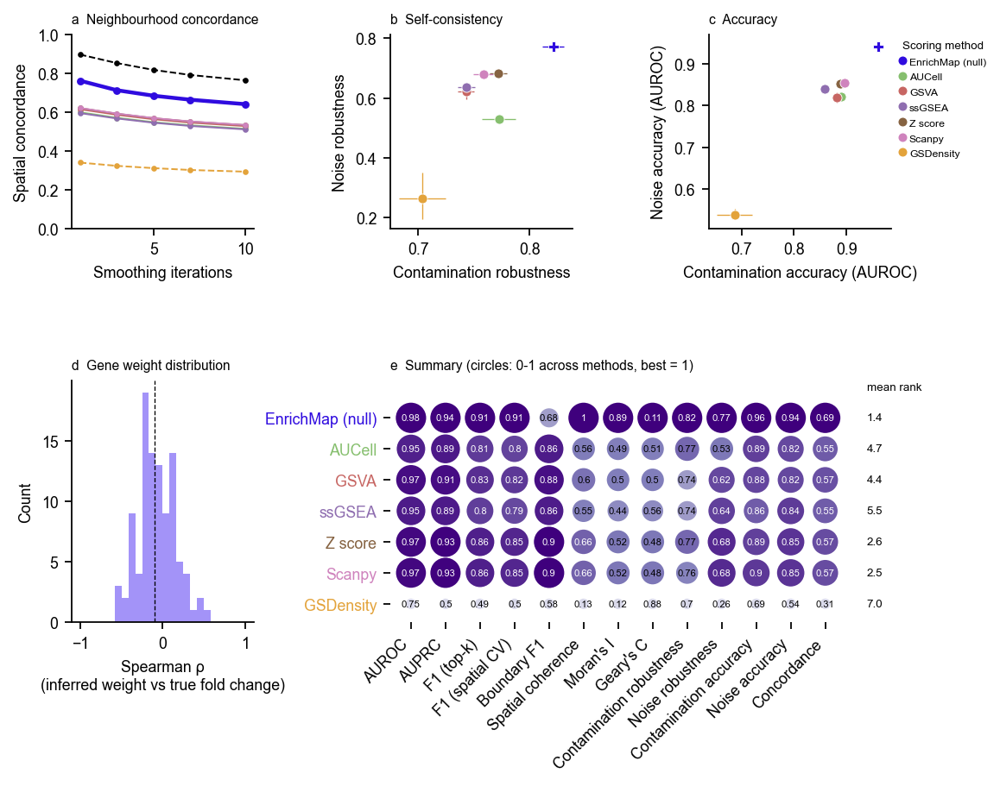

In [30]:
# 25. Extended Data Fig. 1: EnrichMap (null), the comparators without smoothing and GSDensity on the 100 simulated slides
headline_fig = [h for h in headline if h[1] in ("raw", null_config)]
configs_fig = ["raw", null_config]
fig_labels = {"EnrichMap (null model)": "EnrichMap (null)"}
colours_fig = {**colours, "EnrichMap (null)": colours["EnrichMap (null model)"]}
in_fig = pd.DataFrame(headline_fig, columns=["method", "config", "label"])
rob_fig = rob_tab.merge(in_fig[["method", "config"]], on=["method", "config"])

bench_all = pd.concat([
    bench_clf,
    rob_tab.merge(in_fig, on=["method", "config"]).set_index("label")[list(rob_names)],
    conc_tab.merge(in_fig, on=["method", "config"]).set_index("label")[["Concordance, labels smoothed"]],
], axis=1).reindex(in_fig["label"]).rename(index=fig_labels)
bench_all = bench_all.rename(columns={
    "Contamination robustness (ρ)": "Contamination robustness", "Noise robustness (ρ)": "Noise robustness",
    "Contamination accuracy (AUROC)": "Contamination accuracy", "Noise accuracy (AUROC)": "Noise accuracy",
    "Concordance, labels smoothed": "Concordance",
})
print(bench_all.round(3).to_string())

fig = plt.figure(figsize=(7.6, 5.6))
gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[1, 1.25], hspace=0.7, wspace=0.75)
ax = fig.add_subplot(gs[0, 0])
sup_a = f2b_headline_curves(ax, csum[csum.variant == conc_variants[0]], "k", "Spatial concordance",
                            "Smoothing iterations", headline_fig, colours, null_config, ylim=(0, 1.0))
ax.set_title("a  Neighbourhood concordance", fontsize=7, loc="left")
ax = fig.add_subplot(gs[0, 1])
sup_b = f2b_factorial_pair(ax, rob_fig, "Contamination robustness (ρ)", "Noise robustness (ρ)", scorers, configs_fig,
                           plot_style)
ax.set_xlabel("Contamination robustness")
ax.set_ylabel("Noise robustness")
ax.set_title("b  Self-consistency", fontsize=7, loc="left")
ax = fig.add_subplot(gs[0, 2])
sup_c = f2b_factorial_pair(ax, rob_fig, "Contamination accuracy (AUROC)", "Noise accuracy (AUROC)", scorers,
                           configs_fig, plot_style)
ax.set_xlabel("Contamination accuracy (AUROC)")
ax.set_ylabel("Noise accuracy (AUROC)")
ax.set_title("c  Accuracy", fontsize=7, loc="left")
ax.legend(handles=[plt.Line2D([], [], color=colours_fig[label], marker="o", ls="", ms=3.5, label=label)
                   for label in bench_all.index], title="Scoring method", frameon=False, fontsize=5.5, title_fontsize=6,
          loc="upper left", bbox_to_anchor=(1.02, 1.0))
ax = fig.add_subplot(gs[1, 0])
ax.hist(gws[rho_cols[1]], bins=bins, color=colours["EnrichMap (smoothing-only)"])
ax.axvline(gws[rho_cols[1]].median(), color="k", lw=0.6, ls="--")
ax.set_xlabel("Spearman ρ\n(inferred weight vs true fold change)")
ax.set_ylabel("Count")
ax.set_title("d  Gene weight distribution", fontsize=7, loc="left")
ax.grid(False)
sns.despine(ax=ax)
ax = fig.add_subplot(gs[1, 1:])
f2b_plot_benchmark_summary(bench_all, ax, colours_fig, lower_is_better=("Geary's C",))
ax.set_title("e  Summary (circles: 0-1 across methods, best = 1)", fontsize=7, loc="left")
plt.savefig(figure_dir + "ExtendedDataFig1.pdf", bbox_inches="tight")
plt.show()

pd.concat({
    "a": f2b_categorical_to_str(sup_a, labels),
    "b": sup_b,
    "c": sup_c,
    "d": gws[[rho_cols[1]]].reset_index(),
    "e": bench_all.reset_index().rename(columns={"index": "method", "label": "method"}),
}, names=["panel", None]).reset_index(level="panel").replace(
    {"method": fig_labels, "colour key": fig_labels}
).to_csv(source_dir + "ExtendedDataFig1.csv", index=False)

In [31]:
# 27. Key numbers (null model, GAM, smoothing-only and the comparators at their headline configuration)
pair_idx = pair_tab.set_index(["method", "config"])
rob_idx = rob_tab.set_index(["method", "config"])
conc_idx = conc_tab.set_index(["method", "config"])
key = pd.DataFrame({
    label: {
        "AUROC": pair_idx.loc[(m, c), "AUROC"],
        "AUPRC": pair_idx.loc[(m, c), "AUPRC"],
        "F1 (top-k)": pair_idx.loc[(m, c), "F1 (top-k, prevalence-matched)"],
        "Moran's I": pair_idx.loc[(m, c), "Moran's I"],
        "Geary's C": pair_idx.loc[(m, c), "Geary's C"],
        "region-vs-halo AUROC": leak[(leak.method == m) & (leak.config == c)]["region-vs-halo AUROC"].mean(),
        "halo rings 1-3 (SD)": leak[(leak.method == m) & (leak.config == c)]["halo rings 1-3 (far-background SD)"].mean(),
        "contamination robustness (ρ)": rob_idx.loc[(m, c), "Contamination robustness (ρ)"],
        "noise robustness (ρ)": rob_idx.loc[(m, c), "Noise robustness (ρ)"],
        "contamination accuracy (AUROC)": rob_idx.loc[(m, c), "Contamination accuracy (AUROC)"],
        "noise accuracy (AUROC)": rob_idx.loc[(m, c), "Noise accuracy (AUROC)"],
        "concordance (labels smoothed, mean over k)": conc_idx.loc[(m, c), "Concordance, labels smoothed"],
    }
    for m, c, label in headline
}).T
key.index.name = "method"
print(key.round(3).to_string())

                            AUROC  AUPRC  F1 (top-k)  Moran's I  Geary's C  region-vs-halo AUROC  halo rings 1-3 (SD)  contamination robustness (ρ)  noise robustness (ρ)  contamination accuracy (AUROC)  noise accuracy (AUROC)  concordance (labels smoothed, mean over k)
method                                                                                                                                                                                                                                                                       
EnrichMap (null model)      0.978  0.937       0.913      0.888      0.111                 0.941                0.918                         0.822                 0.773                           0.961                   0.940                                       0.694
EnrichMap (smoothing-only)  0.978  0.937       0.913      0.890      0.110                 0.941                0.915                         0.827                 0.778                     